# **Final Project** - Global Shark Attack 
*by Amanda Ang*

**Background**

The Global Shark Attack File dataset provides a detailed record of shark-related incidents worldwide, offering valuable insights into the nature of these interactions. It compiles case histories, documenting key details such as location, activity, species involved, and the extent of injuries. Contrary to common misconceptions, most shark incidents are not aggressive attacks but rather exploratory or defensive behaviors triggered by environmental factors like murky waters or the presence of prey. By analyzing these cases, the dataset helps researchers, medical professionals, and the public understand patterns in shark behavior, contributing to better safety measures for water activities.

Beyond individual case studies, the dataset also sheds light on the ecological significance of sharks and the impact of human activity on their populations. While only a small fraction of shark species pose any real threat to humans, excessive fear and media sensationalism have led to widespread hunting, endangering many species. The Global Shark Attack File aims to dispel these fears by providing factual, forensic-based analyses that emphasize coexistence rather than conflict. By studying shark-related incidents, the dataset promotes informed decision-making, conservation efforts, and responsible ocean practices that protect both people and marine ecosystems.

**Data Dictionary:**
* Date - The date of the shark-related incident
* Year - The year in which the incident occurred.
* Type - The classification of the incident (e.g., Unprovoked, Provoked, Boat-related, etc.).
* Country - The country where the incident took place.
* State - The state or region within the country where the incident occurred.
* Location - The specific beach, bay, or water body where the incident happened.
* Activity - The activity the individual was engaged in at the time of the incident (e.g., Surfing, Swimming, Diving).
* Name - The name of the person involved in the incident.
* Sex -	The gender of the individual (M for male, F for female).
* Age -	The age of the person involved in the incident.
* Injury - A description of the injury sustained during the incident.
* Fatal Y/N - Indicates whether the incident was fatal (Y for Yes, N for No).
* Time - The approximate time when the incident occurred (e.g., 1210 hrs, Unknown).
* Species - The species of shark involved in the incident (if identified).

In [4]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns  
import re
import plotly.express as px
import folium
from folium.plugins import HeatMap
import json
from urllib.request import urlopen
import geopandas as gpd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve, auc, precision_recall_curve, auc as pr_auc, confusion_matrix
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import LabelEncoder
import geopandas as gpd
from scipy.signal import savgol_filter
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm
import mplcursors
import plotly.graph_objects as go
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.combine import SMOTEENN
from sklearn.preprocessing import label_binarize

In [5]:
# Shark Attack Data
df = pd.read_csv(
    "C:\\Users\\amand\\Downloads\\YEAR 2\\Term 3\\Applied Analytical Models\\sharkattacks.csv",
    encoding="ISO-8859-1",
    low_memory=False  
)

# Coordinates of Australia
df_coords = pd.read_csv(
    "C:\\Users\\amand\\Downloads\\YEAR 2\\Term 3\\Applied Analytical Models\\list_coor_australia.csv"
)

## Data Preprocessing

In [7]:
df.head()

,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22
0,10-Mar-25,2025.0,Unprovoked,Australia,WA,Duke of Orleans Bay,Surfing,Steven Jeffrey Payne,M,37,...,Great White Shark,Bob Myatt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,07-Mar-25,2025.0,Unprovoked,Australia,NSW,Gunyah beach Bundeena Port Hacking,Swimming,Mangyong Zhang,F,56,...,Bull shark,Bob Myatt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,27-Feb-25,2025.0,Unprovoked,Australia,Victoria,Nuns Beach near Portland,Swimming,Robbie Houlihan,M,40+,...,Not stated,Kevin McMurray Trackingsharks.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,27-Feb-25,2025.0,Questionable,Philippines,Batangas Resort,Verde Island,SCUBA Diving,Illia Peregudin,M,29,...,Not stated,Stephen Parkhill Glen Folkard,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,22-Feb-25,2025.0,Unprovoked,Australia,Western Australia,Blasck Wall Reach Swan River Perth,Kayaking,Georgina Smith,F,35,...,Not stated,Bob Myatt GSAF,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.columns

Index(['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity',
       'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ',
       'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1',
       'original order', 'Unnamed: 21', 'Unnamed: 22'],
      dtype='object')

In [9]:
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

This removes all columns whose names start with "Unnamed"

In [11]:
df = df.drop(columns=['pdf', 'href formula', 'href', 'Case Number', 'Case Number.1', 'original order', 'Source'])

pdf, href formula, href contain links that are likely not useful for analysis. Case Number, Case Number.1 are likely identifiers for shark attack incidents. Original order seems to be an index column, which is redundant. Source is not valuable

In [13]:
print(df.columns)

Index(['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity',
       'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species '],
      dtype='object')


In [14]:
df.columns = df.columns.str.strip()

In [15]:
df.isna().sum()

Date            0
Year            2
Type           18
Country        50
State         484
Location      566
Activity      585
Name          219
Sex           579
Age          2994
Injury         35
Fatal Y/N     561
Time         3526
Species      3132
dtype: int64

In [16]:
df.shape

(7008, 14)

In [17]:
df

,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,Injury,Fatal Y/N,Time,Species
0,10-Mar-25,2025.0,Unprovoked,Australia,WA,Duke of Orleans Bay,Surfing,Steven Jeffrey Payne,M,37,Missing body not recovered,Y,1210 hrs,Great White Shark
1,07-Mar-25,2025.0,Unprovoked,Australia,NSW,Gunyah beach Bundeena Port Hacking,Swimming,Mangyong Zhang,F,56,Serious lacerations above right knee.,N,1340hrs,Bull shark
2,27-Feb-25,2025.0,Unprovoked,Australia,Victoria,Nuns Beach near Portland,Swimming,Robbie Houlihan,M,40+,minor lacerations to left calf,N,Unknown,Not stated
3,27-Feb-25,2025.0,Questionable,Philippines,Batangas Resort,Verde Island,SCUBA Diving,Illia Peregudin,M,29,both arms severed by sharks after drowning,Y,1300hrs,Not stated
4,22-Feb-25,2025.0,Unprovoked,Australia,Western Australia,Blasck Wall Reach Swan River Perth,Kayaking,Georgina Smith,F,35,None kayak badly damaged by shark,N,0815hrs,Not stated
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7003,Before 1903,0.0,Unprovoked,AUSTRALIA,Western Australia,Roebuck Bay,Diving,male,M,NaN,FATAL,Y,NaN,NaN
7004,Before 1903,0.0,Unprovoked,AUSTRALIA,Western Australia,NaN,Pearl diving,Ahmun,M,NaN,FATAL,Y,NaN,NaN
7005,1900-1905,0.0,Unprovoked,USA,North Carolina,Ocracoke Inlet,Swimming,Coast Guard personnel,M,NaN,FATAL,Y,NaN,NaN
7006,1883-1889,0.0,Unprovoked,PANAMA,NaN,"Panama Bay 8ºN, 79ºW",NaN,Jules Patterson,M,NaN,FATAL,Y,NaN,NaN


In [18]:
df.rename(columns={"Fatal Y/N": "Fatal"}, inplace=True)

categorical_cols = ["Type", "Country", "State", "Location", "Activity", "Name", "Sex", "Injury", "Fatal", "Age", "Time", "Species"]
df[categorical_cols] = df[categorical_cols].fillna("Unknown")

df["Year"] = df["Year"].fillna(0).astype(int)

df["Year"] = df["Year"].replace(2026, 2025)

# Reset index
df.reset_index(drop=True, inplace=True)


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Date      7008 non-null   object
 1   Year      7008 non-null   int32 
 2   Type      7008 non-null   object
 3   Country   7008 non-null   object
 4   State     7008 non-null   object
 5   Location  7008 non-null   object
 6   Activity  7008 non-null   object
 7   Name      7008 non-null   object
 8   Sex       7008 non-null   object
 9   Age       7008 non-null   object
 10  Injury    7008 non-null   object
 11  Fatal     7008 non-null   object
 12  Time      7008 non-null   object
 13  Species   7008 non-null   object
dtypes: int32(1), object(13)
memory usage: 739.3+ KB


In [20]:
df.isna().sum()

Date        0
Year        0
Type        0
Country     0
State       0
Location    0
Activity    0
Name        0
Sex         0
Age         0
Injury      0
Fatal       0
Time        0
Species     0
dtype: int64

In [21]:
print(f"Duplicate rows before removal: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)
print(f"Duplicate rows after removal: {df.duplicated().sum()}")

Duplicate rows before removal: 2
Duplicate rows after removal: 0


In [22]:
df["Sex"] = df["Sex"].str.strip().str.upper()
df["Sex"] = df["Sex"].replace({
    "MALE": "M", 
    "FEMALE": "F", 
    "UNKNOWN": "Unknown"
})

df["Fatal"] = df["Fatal"].str.strip().str.upper()
df["Fatal"] = df["Fatal"].replace({
    "YES": "Y", 
    "NO": "N", 
    "UNKNOWN": "Unknown"
})

valid_sex = ["M", "F", "Unknown"]
valid_fatal = ["Y", "N", "Unknown"]
df = df[df["Sex"].isin(valid_sex) & df["Fatal"].isin(valid_fatal)]

df.reset_index(drop=True, inplace=True)

df[["Sex", "Fatal"]].value_counts()

Sex      Fatal  
M        N          3918
         Y          1246
F        N           607
M        Unknown     450
Unknown  N           360
F        Y           122
Unknown  Unknown     112
         Y           107
F        Unknown      69
Name: count, dtype: int64

In [23]:
len(df['Country'].unique())

243

In [24]:
df.loc[:, 'Country'] = df['Country'].str.strip().str.title()

# Load world map from Natural Earth dataset
world = gpd.read_file("C:\\Users\\amand\\Downloads\\YEAR 2\\Term 3\\Applied Analytical Models\\geo\\ne_110m_admin_0_countries.shp")

geojson_countries = set(world['NAME'].str.title())

country_mapping = {
    "Usa": "United States of America",
    "United States": "United States of America",
    "United States Of America": "United States of America",
    "Dominican Republic": "Dominican Rep.",
    "Cabo Verde": "Cape Verde",
    "Solomon Islands": "Solomon Is.",
    "Falkland Islands (Islas Malvinas)": "Falkland Islands",
    "Equatorial Guinea": "Eq. Guinea",
    "South Sudan": "S. Sudan",
    "West Sahara": "W. Sahara",
    "Palestinian Territory": "Palestine",
    "Micronesia": "Federated States of Micronesia",
    "Hong Kong": "China",
    "Curaçao": "Curaçao",  
    "Réunion": "Réunion",
    "Maldive Islands": "Maldives",
    "Ceylon": "Sri Lanka",
    "Burma": "Myanmar",
    "Persian Gulf": "Iran",  
    "West Indies": "Caribbean Region",
    "Nevis": "Saint Kitts and Nevis",
    "Reunion": "Réunion",
    "Reunion Island": "Réunion",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Trinidad": "Trinidad and Tobago",
    "Tobago": "Trinidad and Tobago",
    "Hawaii": "United States of America",
    "Scotland": "United Kingdom",
    "England": "United Kingdom",
    "Caribbean": "Caribbean Region",
    "Caribbean Sea": "Caribbean Region",
    "Azores": "Portugal",
    "Grand Cayman": "Cayman Islands",
    "Netherlands Antilles": "Caribbean Netherlands",
    "Falkland Islands": "Falkland Islands (UK)",
    "Okinawa": "Japan",
    "Roatan": "Honduras",
    "New Guinea": "Papua New Guinea",
    "Andaman / Nicobar Islandas": "India",
    "St Helena, British Overseas Territory": "Saint Helena",
    "Bahrein": "Bahrain",
    "Sudan?": "Sudan",
    "Korea": "South Korea",  
    "Aruba": "Netherlands",
    "Martinique": "France",
    "Mayotte": "France",
    "Guam": "United States of America",
    "Bermuda": "United Kingdom",
    "Northern Mariana Islands": "United States of America",
    "British Indian Ocean Territory": "United Kingdom",
    "American Samoa": "United States of America",
    "Turks And Caicos": "United Kingdom",
    "Turks & Caicos": "United Kingdom",
    "Saint Kitts And Nevis": "Saint Kitts and Nevis",
    "St Kitts / Nevis": "Saint Kitts and Nevis",
    "St Martin": "France",
    "St. Martin": "France",
    "St. Maartin": "France",
    "Cayman Islands": "Cayman Islands",
    "Saint Helena": "Saint Helena, Ascension and Tristan da Cunha",
    "Palau": "Palau",
    "Marshall Islands": "Marshall Islands",
    "Federated States Of Micronesia": "Federated States of Micronesia",
    "Tonga": "Tonga",
    "Seychelles": "Seychelles",
    "Tuvalu": "Tuvalu",
    "Cook Islands": "New Zealand",
    "Samoa": "Samoa",
    "Barbados": "Barbados",
    "Kiribati": "Kiribati",
    "Comoros": "Comoros",
    "Singapore": "Singapore",
    "Monaco": "Monaco",
    "Cape Verde": "Cape Verde",
    "Bahrain": "Bahrain",
    "Malta": "Malta",
    "Grenada": "Grenada",
    "Mauritius": "Mauritius",
    "Maldives": "Maldives",
    "Jordan": "Jordan",
    "Iraq": "Iraq",
    "Iran": "Iran",
    "Vietnam": "Vietnam",
    "Yemen": "Yemen",
    "Sudan": "Sudan",
    "Somalia": "Somalia",
    "Columbia": "Colombia",  
    "British Overseas Territory": None,  
    "St. Helena, British Overseas Territory": "Saint Helena, Ascension and Tristan da Cunha",
    "Diego Garcia": "United Kingdom",
    "United Arab Emirates (Uae)": "United Arab Emirates",
    "Puerto Rico": "United States of America",
    "Taiwan": "China",
    "Palestinian Territories": "Palestine",
    "United States": "United States of America",
    "Saint Helena": "Saint Helena, Ascension and Tristan da Cunha",
    "Falkland Islands (UK)": "Falkland Islands",
    "Réunion": "Réunion",
    "Trinidad and Tobago": "Trinidad and Tobago",
    "Curacao": "Curaçao",
    "Caribbean Netherlands": "Caribbean Netherlands",
    "Caribbean Region": None,  
    "Caribbean": None,  
    "Cayman Islands": "Cayman Islands",
    "Crete": "Greece",
    "Northern Arabian Sea": None,  
    "British Virgin Islands": "British Virgin Islands",
    "Antigua": "Antigua and Barbuda",
    "Falkland Islands (Uk)": "Falkland Islands",
    "Curaçao": "Curaçao",  
    "Middle East": None,  
}

excluded_regions = {
    "Caribbean", "Europe", "Asia", "Africa", "Middle East", "Oceania", "Unknown",
    "Pacific Ocean", "Atlantic Ocean", "Mediterranean Sea", "Indian Ocean", "North Pacific Ocean",
    "South Pacific Ocean", "North Atlantic Ocean", "South Atlantic Ocean", "Coral Sea", "Tasman Sea",
    "Bay Of Bengal", "Gulf Of Aden", "Red Sea", "Red Sea?", "North Sea", "South China Sea",
    "Mid Atlantic Ocean", "Western Samoa", "Johnston Island", "Andaman Islands", "New Britain",
    "Southwest Pacific Ocean", "Central Pacific", "Mid-Pacifc Ocean", "Admiralty Islands",
    "British West Indies", "Federated States Of Micronesia", "Coast Of Africa", "Indian Ocean?",
    "Ceylon (Sri Lanka)", "Ocean", "Asia?", "Red Sea / Indian Ocean", "Iran / Iraq", "Italy / Croatia",
    "Between Portugal & India", "Equatorial Guinea / Cameroon", "Java", "San Domingo", "British Isles",
    "The Balkans", "British New Guinea"
}
df = df[~df['Country'].isin(excluded_regions)]

df.loc[:, 'Country'] = df['Country'].replace(country_mapping)

unmatched_countries = set(df['Country'].unique()) - geojson_countries

print(df['Country'].unique())

['Australia' 'Philippines' 'Bahamas' 'United Kingdom' 'Mozambique'
 'United States of America' 'New Caledonia' 'Egypt' 'Thailand'
 'New Zealand' 'Maldives' 'Honduras' 'Indonesia' 'Morocco' 'Jamaica'
 'Belize' 'French Polynesia' 'Trinidad and Tobago' 'India' 'South Africa'
 'Mexico' 'Spain' 'Portugal' 'Samoa' 'Colombia' 'Ecuador' 'Cuba' 'Brazil'
 'Seychelles' 'Argentina' 'Fiji' 'Japan' 'Costa Rica' None 'Canada'
 'Jordan' 'Saint Kitts and Nevis' 'France' 'Papua New Guinea' 'Israel'
 'Réunion' 'China' 'Ireland' 'Italy' 'Malaysia' 'Libya' 'Mauritius'
 'Solomon Is.' 'Saint Helena' 'Comoros' 'United Arab Emirates'
 'Cape Verde' 'Dominican Rep.' 'Cayman Islands' 'Netherlands' 'Greece'
 'Kiribati' 'Palestine' 'Nigeria' 'Tonga' 'Croatia' 'Saudi Arabia' 'Chile'
 'Antigua and Barbuda' 'Kenya' 'Russia' 'South Korea' 'Malta' 'Vietnam'
 'Madagascar' 'Panama' 'Somalia' 'British Virgin Islands' 'Norway'
 'Senegal' 'Yemen' 'Sierra Leone' 'Liberia' 'Vanuatu' 'Venezuela'
 'Sri Lanka' 'Uruguay' 'Federate

In [25]:
df["Country"].value_counts()

Country
United States of America    2561
Australia                   1498
South Africa                 597
New Zealand                  147
Papua New Guinea             145
                            ... 
Netherlands                    1
Egypt / Israel                 1
Palestine                      1
British Virgin Islands         1
Bahrain                        1
Name: count, Length: 128, dtype: int64

In [26]:
df['Sex'].unique()

array(['M', 'F', 'Unknown'], dtype=object)

In [27]:
df['Species'].unique()[0:20]

array(['Great White Shark', 'Bull shark', 'Not stated', 'Not stated ',
       'Mako shark', 'bull shark', '1.8m (6ft) bull shark',
       'Bronze whaler', 'Described as a large terrifying animal',
       'Reportedly Tiger or Bull shark',
       'Great White Shart estimated 4.8m 16 ft', 'Unknown',
       'Reportedly a Tiger Shark', 'Unknown ', '1m shark species unknown',
       'Reported as a large Tiger shark', 'Bull or tiger 7-8ft',
       'Bull shark 6ft', 'Large Tiger shark  ', 'Bull shark 6-7ft'],
      dtype=object)

## Exploratory Data Analysis (EDA)

In [29]:
df.shape

(6824, 14)

In [30]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,6824,5818,1957,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,6824.0,NaN,NaN,NaN,1937.8983,266.126842,0.0,1949.0,1988.0,2010.0,2025.0
Type,6824,13,Unprovoked,5074,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,6822,128,United States of America,2561,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,6824,861,Florida,1184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,6824,4502,Unknown,458,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Activity,6824,1510,Surfing,1129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,6824,5612,male,658,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,6824,3,M,5477,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,6824,166,Unknown,2862,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
df.loc[:, "Type"] = df["Type"].str.strip() 

df.loc[:, "Type"] = df["Type"].replace({
    "?": "Unknown",
    "Unconfirmed": "Unknown",
    "Unverified": "Unknown",
    "Invalid": "Unknown",
    "Under investigation": "Unknown",
    "Boat": "Watercraft"
})

print(df["Fatal"].value_counts()) 
print(df["Sex"].value_counts())    
print(df["Country"].value_counts().head(10))  
print(df["Type"].value_counts())

Fatal
N          4807
Y          1402
Unknown     615
Name: count, dtype: int64
Sex
M          5477
F           788
Unknown     559
Name: count, dtype: int64
Country
United States of America    2561
Australia                   1498
South Africa                 597
New Zealand                  147
Papua New Guinea             145
Bahamas                      139
Brazil                       122
Mexico                       106
Italy                         71
Fiji                          70
Name: count, dtype: int64
Type
Unprovoked      5074
Provoked         625
Unknown          559
Watercraft       354
Sea Disaster     189
Questionable      23
Name: count, dtype: int64


### Data Visualization

#### Gender Distribution of Shark Attack Victims

C:\Users\amand\AppData\Local\Temp\ipykernel_97160\1182306429.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontsize=11)


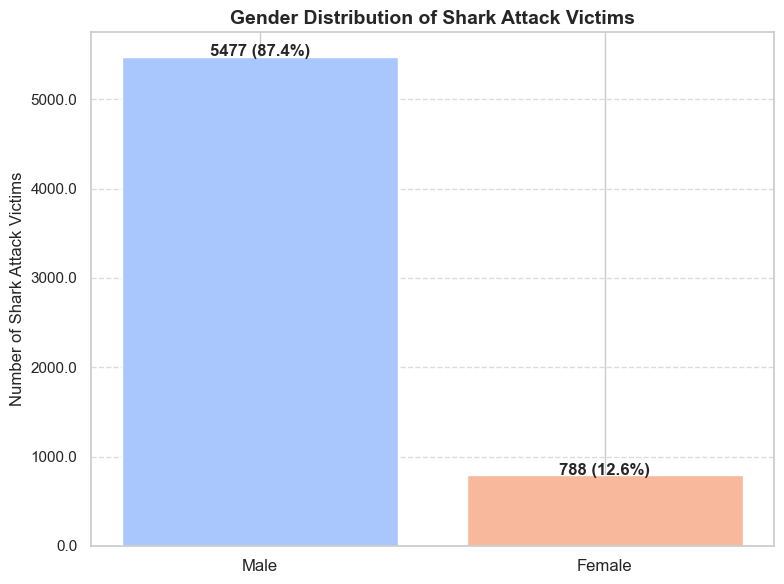

In [34]:
df_filtered = df[df['Sex'].isin(['M', 'F'])]

gender_counts = df_filtered['Sex'].value_counts()

gender_counts = gender_counts.rename(index={'M': 'Male', 'F': 'Female'})

sns.set(style="whitegrid")

fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(gender_counts.index, gender_counts.values, color=sns.color_palette("coolwarm", 2))

total = gender_counts.sum()
for i, v in enumerate(gender_counts.values):
    percentage = (v / total) * 100
    ax.text(i, v + 5, f"{v} ({percentage:.1f}%)", ha='center', fontsize=12, fontweight='bold')

ax.set_ylabel("Number of Shark Attack Victims", fontsize=12)
ax.set_title("Gender Distribution of Shark Attack Victims", fontsize=14, fontweight='bold')

ax.set_xticks(range(len(gender_counts))) 
ax.set_xticklabels(gender_counts.index, fontsize=12)
ax.set_yticklabels(ax.get_yticks(), fontsize=11)

ax.grid(axis='y', linestyle='--', alpha=0.7)

ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=11)

plt.tight_layout()
plt.show()

#### Shark Attack Fatality Rate by Gender

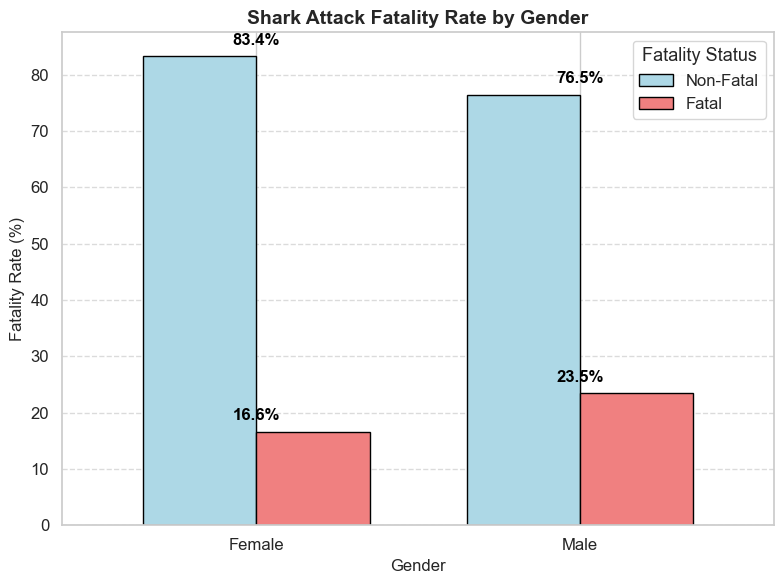

In [36]:
fatality_by_gender = df_filtered.groupby(['Sex', 'Fatal']).size().unstack()
fatality_by_gender = fatality_by_gender[['N', 'Y']]  
fatality_by_gender = fatality_by_gender.div(fatality_by_gender.sum(axis=1), axis=0) * 100 

fatality_by_gender.columns = ['Non-Fatal (%)', 'Fatal (%)']
fatality_by_gender.index = fatality_by_gender.index.map({'M': 'Male', 'F': 'Female'})

sns.set(style="whitegrid")

fig, ax = plt.subplots(figsize=(8, 6))

fatality_by_gender.plot(kind='bar', ax=ax, color=['lightblue', 'lightcoral'], edgecolor='black', width=0.7)

for i, row in enumerate(fatality_by_gender.values):
    for j, value in enumerate(row):
        ax.text(i, value + 2, f"{value:.1f}%", ha='center', fontsize=12, fontweight='bold', color='black')

ax.set_xlabel("Gender", fontsize=12)
ax.set_ylabel("Fatality Rate (%)", fontsize=12)
ax.set_title("Shark Attack Fatality Rate by Gender", fontsize=14, fontweight='bold')
ax.set_xticklabels(fatality_by_gender.index, fontsize=12, rotation=0)

ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)

ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.legend(title="Fatality Status", labels=['Non-Fatal', 'Fatal'], fontsize=12, title_fontsize=13)

# Show the plot
plt.tight_layout()
plt.show()

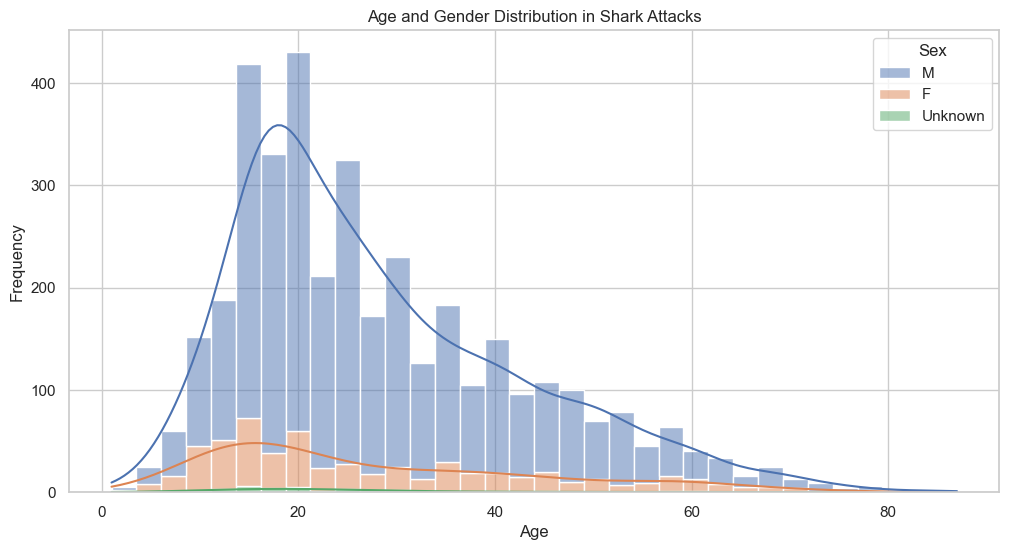

In [37]:
df_filtered_age = df[df['Age'] != 'Unknown']

df_filtered_age.loc[:, 'Age'] = pd.to_numeric(df_filtered_age['Age'], errors='coerce')

df_filtered_age = df_filtered_age.dropna(subset=['Age'])

plt.figure(figsize=(12, 6))
sns.histplot(df_filtered_age, x='Age', hue='Sex', multiple='stack', kde=True)
plt.title('Age and Gender Distribution in Shark Attacks')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()


#### Top 10 Most Common Shark Species by Fatality Status

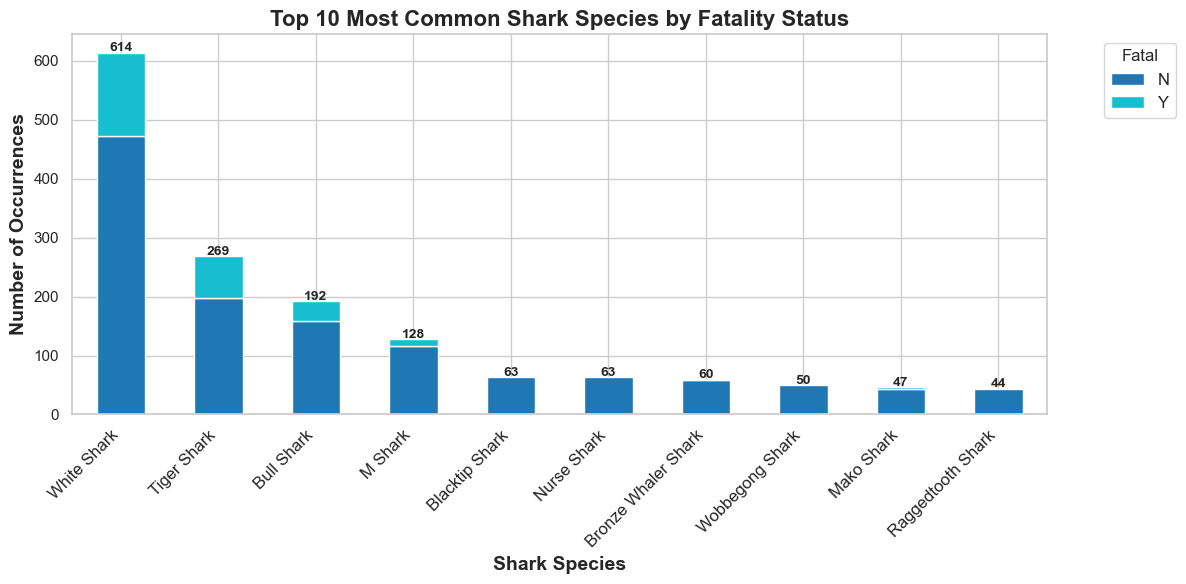

In [39]:
df['Species'] = df['Species'].fillna('Unknown shark')
df['Fatal'] = df['Fatal'].fillna('Unknown')

df['New Species'] = None

shark_pattern = r'(\b[A-Za-z\s-]+\b)\s+shark'

for row in range(len(df)):
    try:
        match = re.search(shark_pattern, df.iat[row, df.columns.get_loc('Species')], re.IGNORECASE)
        if match:
            df.iat[row, df.columns.get_loc('New Species')] = match.group(1).title() + ' Shark'
        else:
            df.iat[row, df.columns.get_loc('New Species')] = "Shark involvement not confirmed"
    except:
        df.iat[row, df.columns.get_loc('New Species')] = "Shark involvement not confirmed"

species_fatal_counts = df.groupby(['New Species', 'Fatal']).size().unstack(fill_value=0)

species_fatal_counts = species_fatal_counts.loc[~species_fatal_counts.index.isin(['Unknown shark', 'Shark involvement not confirmed'])]
species_fatal_counts = species_fatal_counts.drop(columns=['Unknown'], errors='ignore')

top_10_species = species_fatal_counts.sum(axis=1).nlargest(10).index
species_fatal_counts = species_fatal_counts.loc[top_10_species]

fig, ax = plt.subplots(figsize=(12, 6))
species_fatal_counts.plot(kind='bar', stacked=True, ax=ax, colormap='tab10')

plt.title('Top 10 Most Common Shark Species by Fatality Status', fontsize=16, fontweight='bold')
plt.xlabel('Shark Species', fontsize=14, fontweight='bold')
plt.ylabel('Number of Occurrences', fontsize=14, fontweight='bold')

plt.xticks(rotation=45, ha='right', fontsize=12)

plt.legend(title='Fatal', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=12)

total_victims = species_fatal_counts.sum(axis=1)
for i, (species, value) in enumerate(total_victims.items()):
    ax.text(i, value + 2, str(value), ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()

plt.show()

#### Top 5 Countries with the Highest Frequency of Shark Attacks

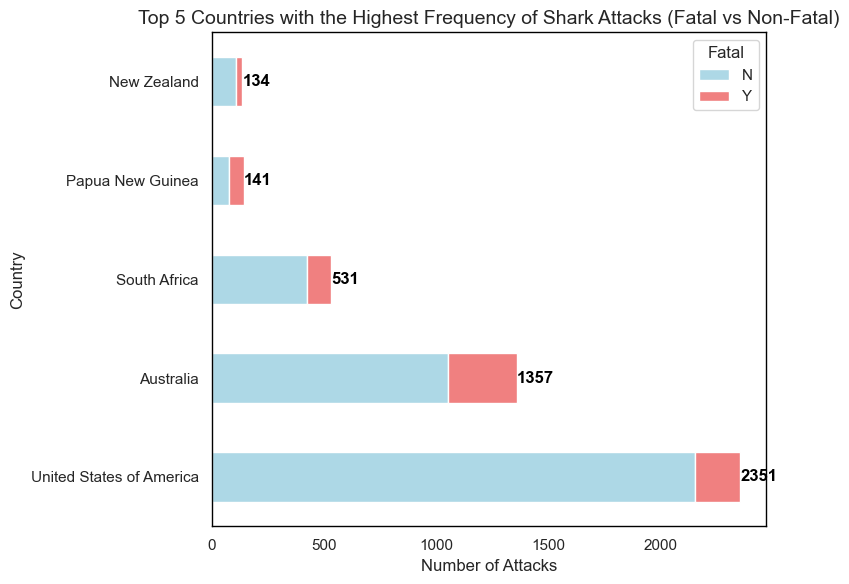

In [41]:
country_fatal_grp = df.groupby(['Country', 'Fatal']).size().unstack(fill_value=0)

country_fatal_grp = country_fatal_grp.loc[:, ~country_fatal_grp.columns.str.contains('Unknown', case=False)]

top_5_countries = country_fatal_grp.sum(axis=1).nlargest(5).index

top_5_country_data = country_fatal_grp.loc[top_5_countries]

fig, ax = plt.subplots(figsize=(8, 6))
top_5_country_data.plot(kind='barh', stacked=True, ax=ax, color=['lightblue', 'lightcoral'])

plt.xlabel('Number of Attacks', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.title('Top 5 Countries with the Highest Frequency of Shark Attacks (Fatal vs Non-Fatal)', fontsize=14)

for i, country in enumerate(top_5_country_data.index):
    total_attacks = top_5_country_data.loc[country].sum()
    ax.text(total_attacks + 1, i, str(total_attacks), ha='left', va='center', fontsize=12, fontweight='bold', color='black')

ax.grid(False)

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1)  
    
plt.tight_layout()
plt.show()

#### World map of Shark Incidents by Country

In [43]:
shark_incidents = df.groupby('Country').size().reset_index(name='Incidents')

world = gpd.read_file("C:\\Users\\amand\\Downloads\\YEAR 2\\Term 3\\Applied Analytical Models\\geo\\ne_110m_admin_0_countries.shp")

world = world.merge(shark_incidents, how='left', left_on='NAME', right_on='Country')

fig = px.choropleth(
    world,
    geojson=world.geometry,
    locations=world.index,
    color='Incidents',
    hover_name='NAME',
    hover_data={'Incidents': True},
    title='Global Shark Incidents by Country',
    color_continuous_scale='Reds'
)

fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(
    coloraxis_colorbar=dict(
        title='Shark Incidents',
        orientation='h',  
        x=0.5,  
        y=-0.2  
    ),
    width=1200,
    height=800
)

fig.show()

### Scatter map of shark incidents in Australia

In [45]:
df_coords.columns = ["Latitude", "Longitude"]

australia_center = [-25.2744, 133.7751]

shark_map = folium.Map(location=australia_center, zoom_start=4)

heat_data = df_coords[["Latitude", "Longitude"]].values.tolist()
HeatMap(heat_data).add_to(shark_map)

shark_map

### Types of Shark Attack Incidents

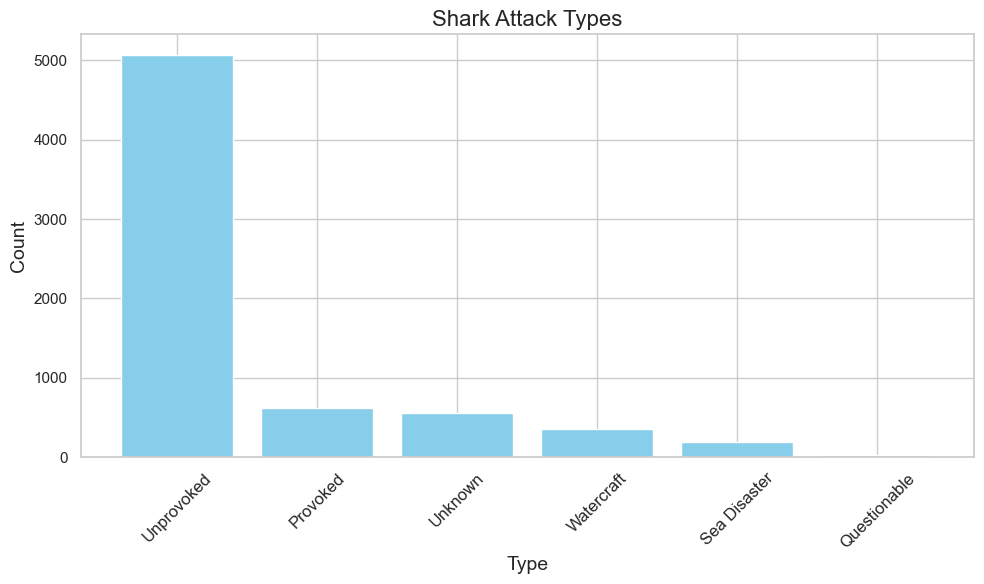

,Type,Count
0,Unprovoked,5074
1,Provoked,625
2,Unknown,559
3,Watercraft,354
4,Sea Disaster,189
5,Questionable,23


In [47]:
type_counts = df["Type"].value_counts().reset_index()
type_counts.columns = ['Type', 'Count']

plt.figure(figsize=(10, 6))
plt.bar(type_counts['Type'], type_counts['Count'], color='skyblue')
plt.xlabel('Type', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.title('Shark Attack Types', fontsize=16)
plt.xticks(rotation=45, fontsize=12)
plt.tight_layout()

plt.show()

type_counts

### Provoked Attacks by Activity 

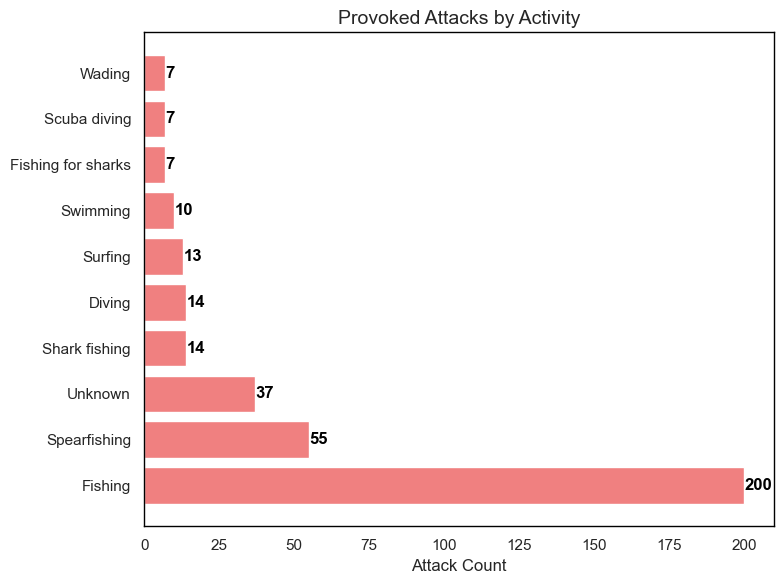

In [49]:
prov_activity = df[df['Type'] == 'Provoked'].groupby('Activity')['Activity'].count().sort_values(ascending=False)[:10]

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(prov_activity.index, prov_activity.values, color='lightcoral')

plt.xlabel('Attack Count', fontsize=12)
plt.title('Provoked Attacks by Activity', fontsize=14)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1)

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.1, bar.get_y() + bar.get_height() / 2, 
            f'{width}', va='center', ha='left', fontsize=12, fontweight='bold', color='black')

plt.tight_layout()
plt.show()


In [50]:
df.columns

Index(['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity',
       'Name', 'Sex', 'Age', 'Injury', 'Fatal', 'Time', 'Species',
       'New Species'],
      dtype='object')

### Machine Learning Models

#### Classification Modelling with Resampling Techniques


========== RESULTS USING VARIOUS RESAMPLING METHODS ==========

Resampling Method: Random OverSampling

Model: Logistic Regression with Random OverSampling
Confusion Matrix:
[[ 65   0   1   2  49  11]
 [  0   0   0   0   5   1]
 [  1   0  17   0  13   0]
 [  1   0   0  85   6   0]
 [ 45   0  19   5 958   9]
 [ 11   0   0   0   6  55]]


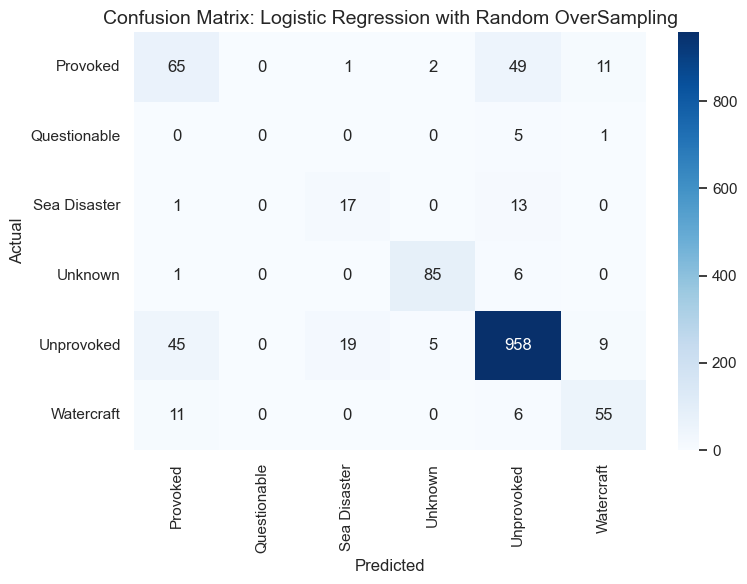

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.53      0.51      0.52       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.46      0.55      0.50        31
     Unknown       0.92      0.92      0.92        92
  Unprovoked       0.92      0.92      0.92      1036
  Watercraft       0.72      0.76      0.74        72

    accuracy                           0.86      1365
   macro avg       0.59      0.61      0.60      1365
weighted avg       0.86      0.86      0.86      1365

Accuracy Score: 0.8645
ROC AUC Score: 0.9258
PR AUC Score: -0.9358
------------------------------------------------------------

Model: Decision Tree with Random OverSampling
Confusion Matrix:
[[ 70   0   4   4  41   9]
 [  0   1   0   0   5   0]
 [  1   0  18   0  12   0]
 [  1   0   1  85   5   0]
 [ 90  15  48  13 851  19]
 [ 11   0   0   0  12  49]]


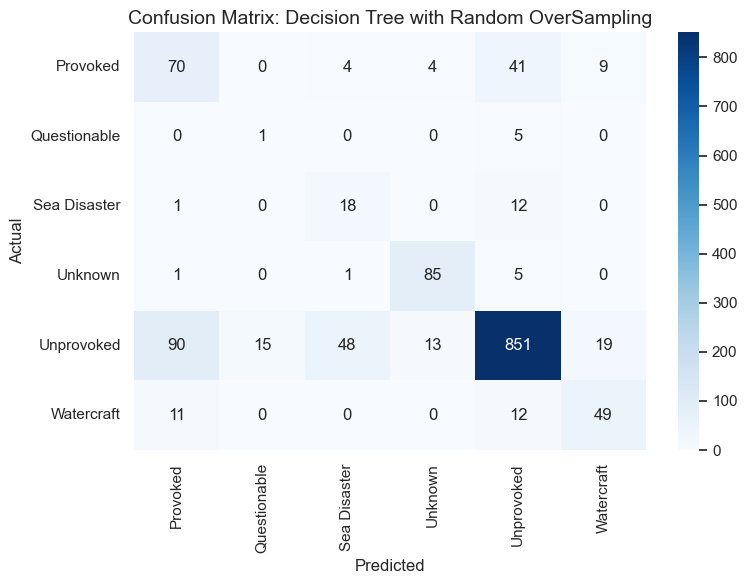

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.40      0.55      0.47       128
Questionable       0.06      0.17      0.09         6
Sea Disaster       0.25      0.58      0.35        31
     Unknown       0.83      0.92      0.88        92
  Unprovoked       0.92      0.82      0.87      1036
  Watercraft       0.64      0.68      0.66        72

    accuracy                           0.79      1365
   macro avg       0.52      0.62      0.55      1365
weighted avg       0.83      0.79      0.80      1365

Accuracy Score: 0.7868
ROC AUC Score: 0.7769
PR AUC Score: -0.8046
------------------------------------------------------------

Model: Random Forest with Random OverSampling
Confusion Matrix:
[[  32    0    0    1   88    7]
 [   0    0    0    0    6    0]
 [   0    0    5    0   26    0]
 [   0    0    0   85    7    0]
 [  13    0    1    4 1016    2]
 [   4    0    0    1   24   43]]


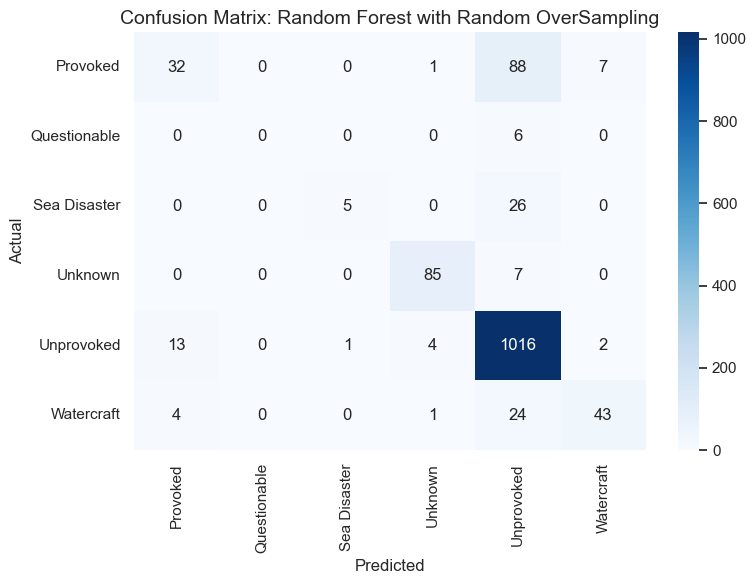

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.65      0.25      0.36       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.83      0.16      0.27        31
     Unknown       0.93      0.92      0.93        92
  Unprovoked       0.87      0.98      0.92      1036
  Watercraft       0.83      0.60      0.69        72

    accuracy                           0.87      1365
   macro avg       0.69      0.49      0.53      1365
weighted avg       0.85      0.87      0.84      1365

Accuracy Score: 0.8652
ROC AUC Score: 0.8833
PR AUC Score: -0.9260
------------------------------------------------------------

Model: Support Vector Machine with Random OverSampling
Confusion Matrix:
[[ 60   0   2   2  53  11]
 [  0   0   0   0   6   0]
 [  1   0  12   0  18   0]
 [  1   0   0  85   6   0]
 [ 35   0  11   8 974   8]
 [  9   0   0   1   9  53]]


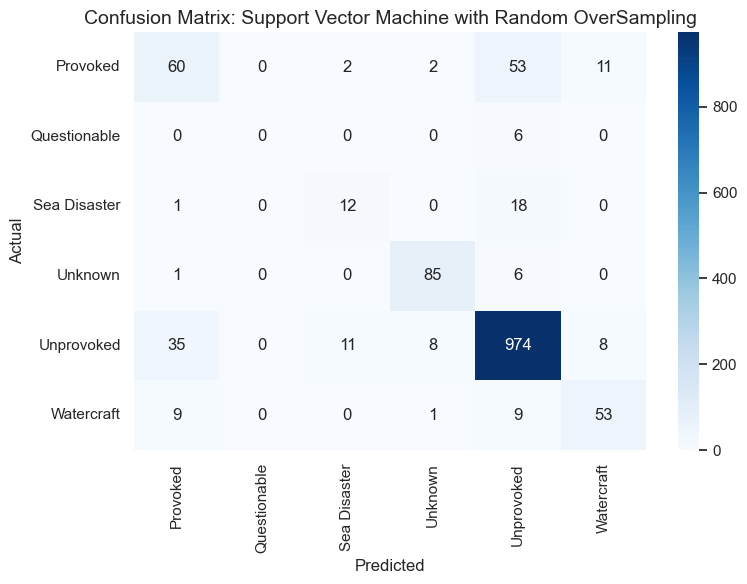

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.57      0.47      0.51       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.48      0.39      0.43        31
     Unknown       0.89      0.92      0.90        92
  Unprovoked       0.91      0.94      0.93      1036
  Watercraft       0.74      0.74      0.74        72

    accuracy                           0.87      1365
   macro avg       0.60      0.58      0.58      1365
weighted avg       0.86      0.87      0.86      1365

Accuracy Score: 0.8674
ROC AUC Score: 0.8539
PR AUC Score: -0.9188
------------------------------------------------------------

Resampling Method: Random UnderSampling

Model: Logistic Regression with Random UnderSampling
Confusion Matrix:
[[ 74   7  12   1  19  15]
 [  1   2   0   0   2   1]
 [  2   2  18   0   9   0]
 [  1   2   3  81   3   2]
 [304 143 175  10 374  30]
 [ 21   0   7   0   0  44]]


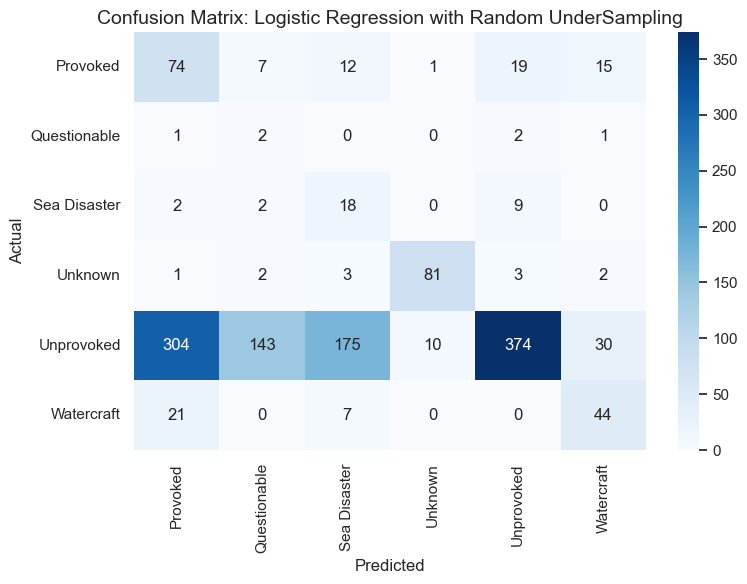

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.18      0.58      0.28       128
Questionable       0.01      0.33      0.02         6
Sea Disaster       0.08      0.58      0.15        31
     Unknown       0.88      0.88      0.88        92
  Unprovoked       0.92      0.36      0.52      1036
  Watercraft       0.48      0.61      0.54        72

    accuracy                           0.43      1365
   macro avg       0.43      0.56      0.40      1365
weighted avg       0.80      0.43      0.51      1365

Accuracy Score: 0.4344
ROC AUC Score: 0.7919
PR AUC Score: -0.4284
------------------------------------------------------------

Model: Decision Tree with Random UnderSampling
Confusion Matrix:
[[ 51  14  23   1  29  10]
 [  0   6   0   0   0   0]
 [  4   1  12   0  14   0]
 [  3   4  14  71   0   0]
 [322 126 163   6 405  14]
 [ 15   1   8   0   5  43]]


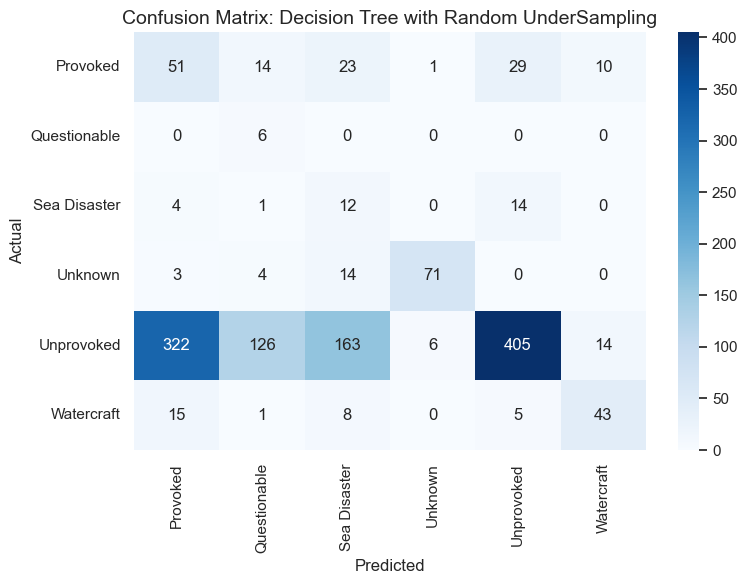

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.13      0.40      0.20       128
Questionable       0.04      1.00      0.08         6
Sea Disaster       0.05      0.39      0.10        31
     Unknown       0.91      0.77      0.84        92
  Unprovoked       0.89      0.39      0.54      1036
  Watercraft       0.64      0.60      0.62        72

    accuracy                           0.43      1365
   macro avg       0.44      0.59      0.39      1365
weighted avg       0.79      0.43      0.52      1365

Accuracy Score: 0.4308
ROC AUC Score: 0.7362
PR AUC Score: -0.4782
------------------------------------------------------------

Model: Random Forest with Random UnderSampling
Confusion Matrix:
[[ 70   3  14   3  18  20]
 [  1   2   1   0   2   0]
 [  1   0  23   0   6   1]
 [  0   2   3  83   3   1]
 [260  69 195  16 441  55]
 [ 14   1   5   0   1  51]]


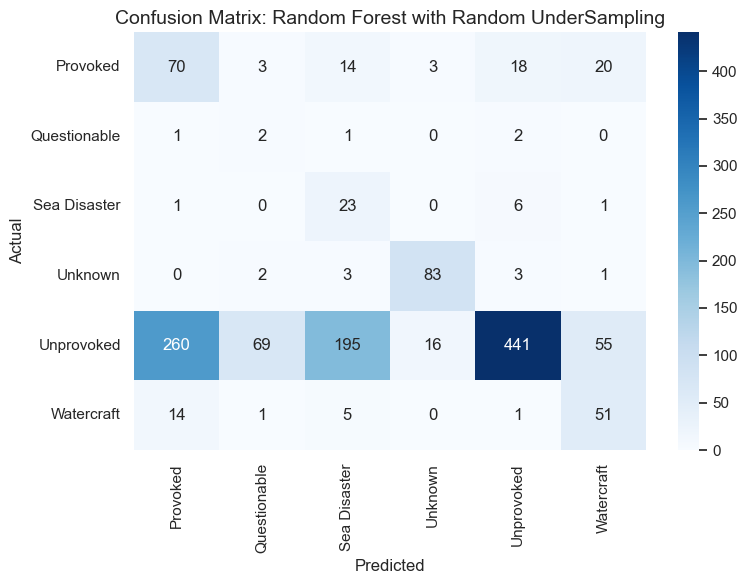

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.20      0.55      0.30       128
Questionable       0.03      0.33      0.05         6
Sea Disaster       0.10      0.74      0.17        31
     Unknown       0.81      0.90      0.86        92
  Unprovoked       0.94      0.43      0.59      1036
  Watercraft       0.40      0.71      0.51        72

    accuracy                           0.49      1365
   macro avg       0.41      0.61      0.41      1365
weighted avg       0.81      0.49      0.56      1365

Accuracy Score: 0.4908
ROC AUC Score: 0.8368
PR AUC Score: -0.5213
------------------------------------------------------------

Model: Support Vector Machine with Random UnderSampling
Confusion Matrix:
[[ 74   4   6   1  31  12]
 [  1   1   0   0   3   1]
 [  1   2  19   0   9   0]
 [  2   4   1  82   1   2]
 [358 105 143  11 404  15]
 [ 19   0   6   0   4  43]]


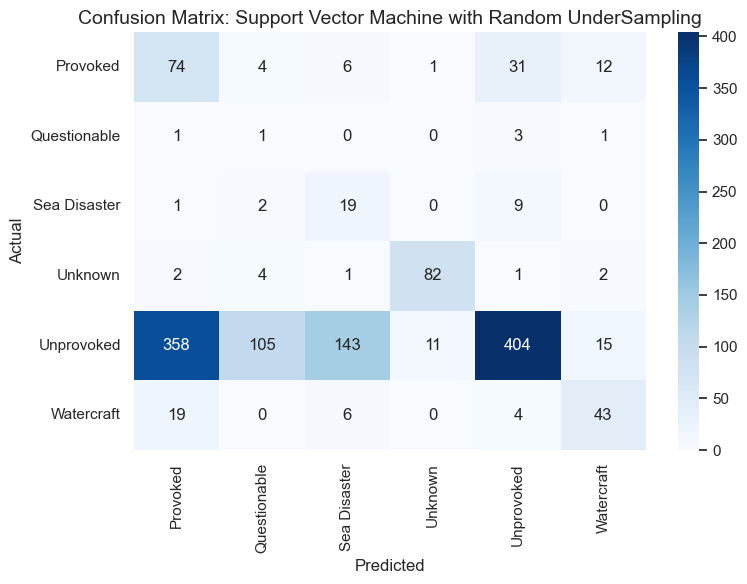

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.16      0.58      0.25       128
Questionable       0.01      0.17      0.02         6
Sea Disaster       0.11      0.61      0.18        31
     Unknown       0.87      0.89      0.88        92
  Unprovoked       0.89      0.39      0.54      1036
  Watercraft       0.59      0.60      0.59        72

    accuracy                           0.46      1365
   macro avg       0.44      0.54      0.41      1365
weighted avg       0.79      0.46      0.53      1365

Accuracy Score: 0.4564
ROC AUC Score: 0.7514
PR AUC Score: -0.4195
------------------------------------------------------------

Resampling Method: SMOTE

Model: Logistic Regression with SMOTE
Confusion Matrix:
[[ 65   0   1   2  49  11]
 [  0   0   0   1   4   1]
 [  1   0  16   0  14   0]
 [  1   0   0  85   6   0]
 [ 39   0  20   4 964   9]
 [ 11   0   0   0   6  55]]


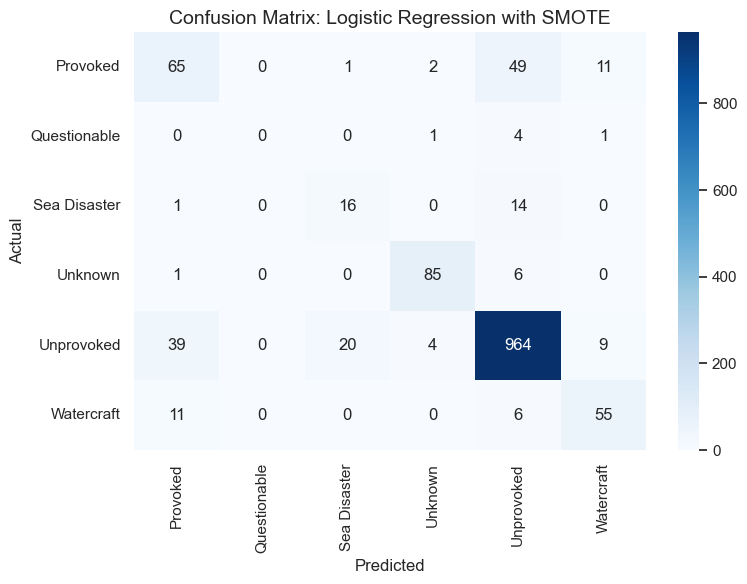

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.56      0.51      0.53       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.43      0.52      0.47        31
     Unknown       0.92      0.92      0.92        92
  Unprovoked       0.92      0.93      0.93      1036
  Watercraft       0.72      0.76      0.74        72

    accuracy                           0.87      1365
   macro avg       0.59      0.61      0.60      1365
weighted avg       0.86      0.87      0.87      1365

Accuracy Score: 0.8681
ROC AUC Score: 0.9248
PR AUC Score: -0.9354
------------------------------------------------------------

Model: Decision Tree with SMOTE
Confusion Matrix:
[[ 50   0   2   2  60  14]
 [  0   0   0   1   5   0]
 [  2   0  11   0  18   0]
 [  0   1   0  85   6   0]
 [ 56   3  35   6 927   9]
 [ 10   0   0   0   9  53]]


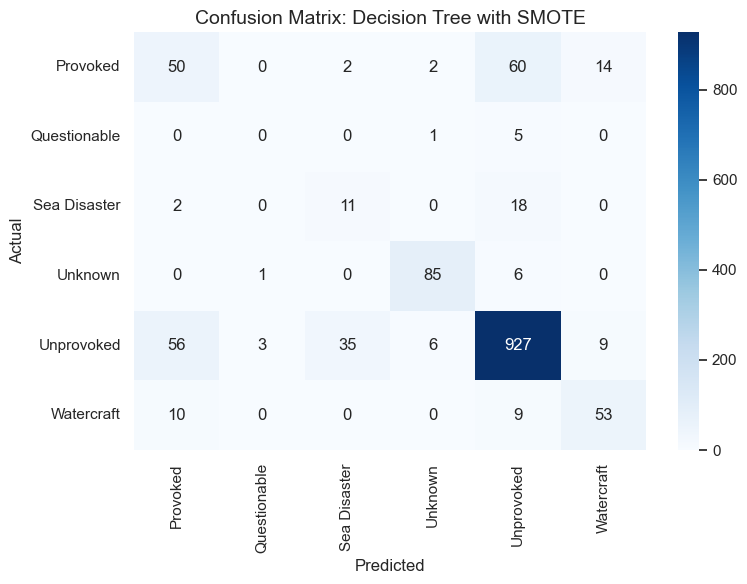

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.42      0.39      0.41       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.23      0.35      0.28        31
     Unknown       0.90      0.92      0.91        92
  Unprovoked       0.90      0.89      0.90      1036
  Watercraft       0.70      0.74      0.72        72

    accuracy                           0.82      1365
   macro avg       0.53      0.55      0.54      1365
weighted avg       0.83      0.82      0.83      1365

Accuracy Score: 0.8249
ROC AUC Score: 0.7410
PR AUC Score: -0.8395
------------------------------------------------------------

Model: Random Forest with SMOTE
Confusion Matrix:
[[  17    0    0    1  103    7]
 [   0    0    0    0    6    0]
 [   0    0    5    0   26    0]
 [   0    0    0   83    9    0]
 [   3    0    1    4 1024    4]
 [   5    0    0    0   25   42]]


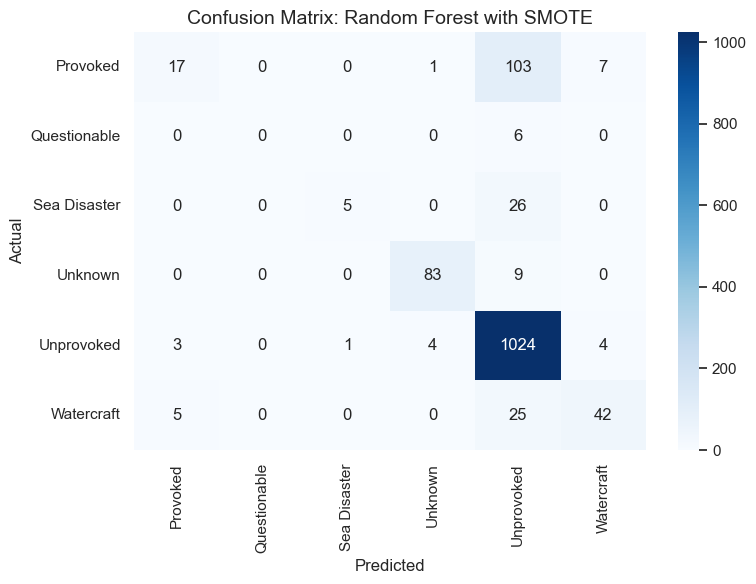

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.68      0.13      0.22       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.83      0.16      0.27        31
     Unknown       0.94      0.90      0.92        92
  Unprovoked       0.86      0.99      0.92      1036
  Watercraft       0.79      0.58      0.67        72

    accuracy                           0.86      1365
   macro avg       0.68      0.46      0.50      1365
weighted avg       0.84      0.86      0.82      1365

Accuracy Score: 0.8579
ROC AUC Score: 0.8644
PR AUC Score: -0.9150
------------------------------------------------------------

Model: Support Vector Machine with SMOTE
Confusion Matrix:
[[ 98   0   3   2  15  10]
 [  1   0   0   0   5   0]
 [  5   0  14   0  12   0]
 [  3   0   0  85   4   0]
 [174   0  19   9 823  11]
 [ 12   0   0   1   5  54]]


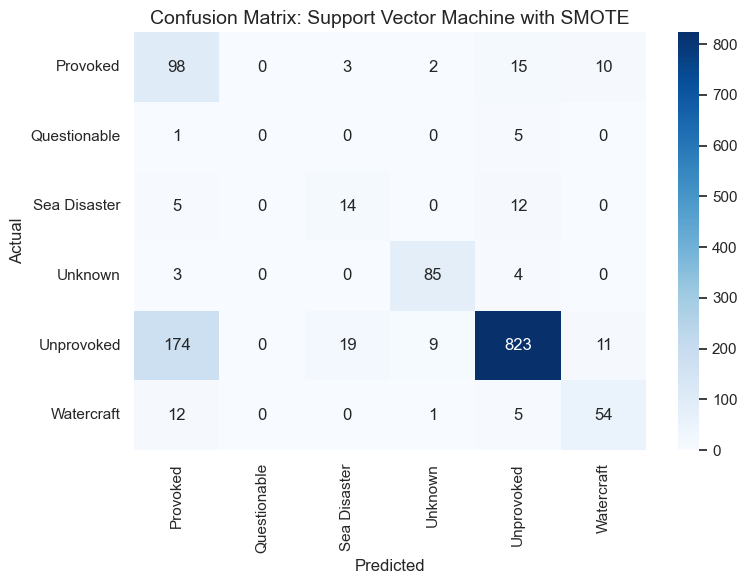

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.33      0.77      0.47       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.39      0.45      0.42        31
     Unknown       0.88      0.92      0.90        92
  Unprovoked       0.95      0.79      0.87      1036
  Watercraft       0.72      0.75      0.73        72

    accuracy                           0.79      1365
   macro avg       0.55      0.61      0.56      1365
weighted avg       0.86      0.79      0.81      1365

Accuracy Score: 0.7868
ROC AUC Score: 0.8922
PR AUC Score: -0.8545
------------------------------------------------------------

Resampling Method: ADASYN

Model: Logistic Regression with ADASYN
Confusion Matrix:
[[ 67   0   1   2  47  11]
 [  0   0   0   1   4   1]
 [  1   0  16   0  14   0]
 [  1   0   0  85   6   0]
 [ 39   0  20   4 965   8]
 [ 11   0   0   0   6  55]]


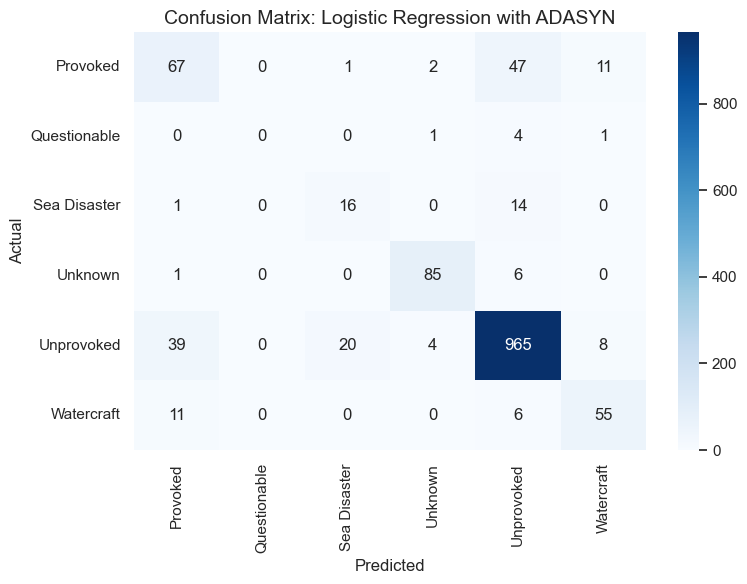

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.56      0.52      0.54       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.43      0.52      0.47        31
     Unknown       0.92      0.92      0.92        92
  Unprovoked       0.93      0.93      0.93      1036
  Watercraft       0.73      0.76      0.75        72

    accuracy                           0.87      1365
   macro avg       0.60      0.61      0.60      1365
weighted avg       0.87      0.87      0.87      1365

Accuracy Score: 0.8703
ROC AUC Score: 0.9249
PR AUC Score: -0.9358
------------------------------------------------------------

Model: Decision Tree with ADASYN
Confusion Matrix:
[[ 52   0   2   3  58  13]
 [  0   1   0   1   4   0]
 [  2   0  17   0  12   0]
 [  0   1   0  83   8   0]
 [ 42   4  33   9 933  15]
 [  7   0   1   0   8  56]]


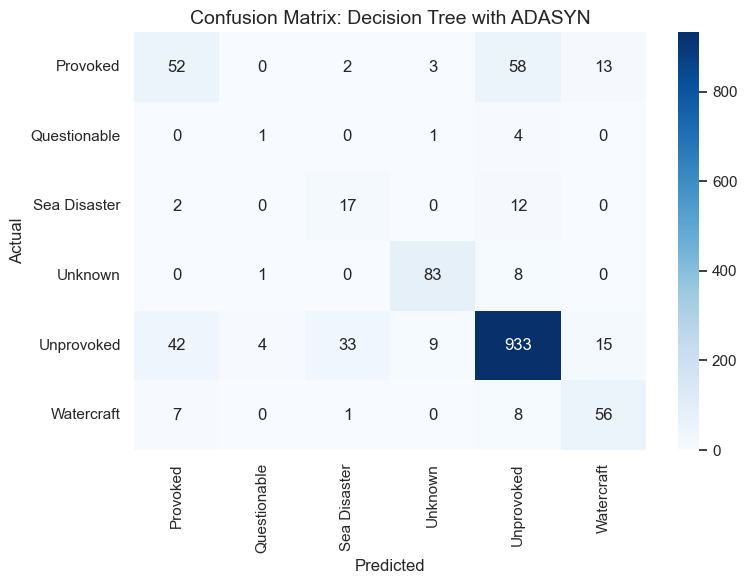

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.50      0.41      0.45       128
Questionable       0.17      0.17      0.17         6
Sea Disaster       0.32      0.55      0.40        31
     Unknown       0.86      0.90      0.88        92
  Unprovoked       0.91      0.90      0.91      1036
  Watercraft       0.67      0.78      0.72        72

    accuracy                           0.84      1365
   macro avg       0.57      0.62      0.59      1365
weighted avg       0.84      0.84      0.84      1365

Accuracy Score: 0.8366
ROC AUC Score: 0.7770
PR AUC Score: -0.8502
------------------------------------------------------------

Model: Random Forest with ADASYN
Confusion Matrix:
[[  19    0    0    1   98   10]
 [   0    0    0    0    6    0]
 [   0    0    6    0   25    0]
 [   0    0    0   84    8    0]
 [   8    0    1    4 1021    2]
 [   4    0    0    1   23   44]]


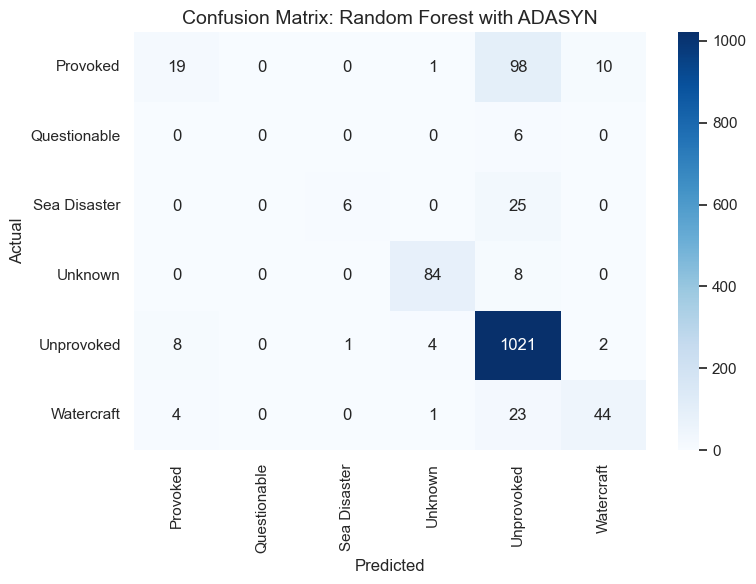

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.61      0.15      0.24       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.86      0.19      0.32        31
     Unknown       0.93      0.91      0.92        92
  Unprovoked       0.86      0.99      0.92      1036
  Watercraft       0.79      0.61      0.69        72

    accuracy                           0.86      1365
   macro avg       0.68      0.48      0.51      1365
weighted avg       0.84      0.86      0.83      1365

Accuracy Score: 0.8601
ROC AUC Score: 0.8724
PR AUC Score: -0.9202
------------------------------------------------------------

Model: Support Vector Machine with ADASYN
Confusion Matrix:
[[ 97   0   3   2  16  10]
 [  1   0   0   0   5   0]
 [  4   0  14   0  13   0]
 [  3   0   0  85   4   0]
 [157   0  19   9 842   9]
 [ 13   0   0   1   5  53]]


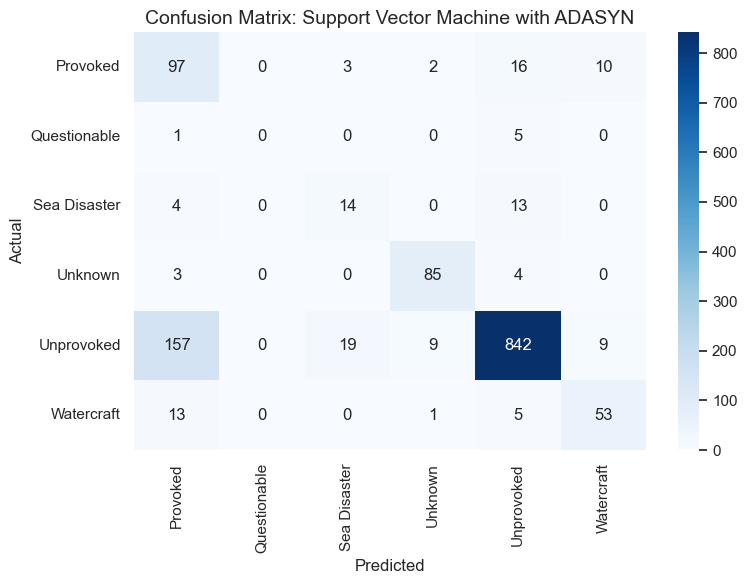

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.35      0.76      0.48       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.39      0.45      0.42        31
     Unknown       0.88      0.92      0.90        92
  Unprovoked       0.95      0.81      0.88      1036
  Watercraft       0.74      0.74      0.74        72

    accuracy                           0.80      1365
   macro avg       0.55      0.61      0.57      1365
weighted avg       0.86      0.80      0.82      1365

Accuracy Score: 0.7993
ROC AUC Score: 0.8740
PR AUC Score: -0.8770
------------------------------------------------------------

Resampling Method: Tomek Links (Undersampling)

Model: Logistic Regression with Tomek Links (Undersampling)
Confusion Matrix:
[[ 78   0   3   2  34  11]
 [  0   0   0   0   5   1]
 [  2   0  20   0   9   0]
 [  1   0   0  85   6   0]
 [ 60   0  28   8 927  13]
 [ 11   0   0   0   6  55]]


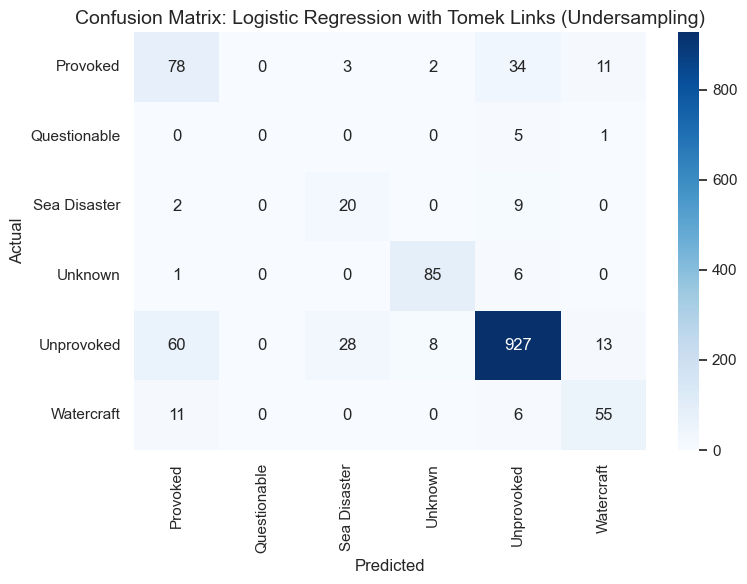

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.51      0.61      0.56       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.39      0.65      0.49        31
     Unknown       0.89      0.92      0.91        92
  Unprovoked       0.94      0.89      0.92      1036
  Watercraft       0.69      0.76      0.72        72

    accuracy                           0.85      1365
   macro avg       0.57      0.64      0.60      1365
weighted avg       0.87      0.85      0.86      1365

Accuracy Score: 0.8535
ROC AUC Score: 0.9227
PR AUC Score: -0.9193
------------------------------------------------------------

Model: Decision Tree with Tomek Links (Undersampling)
Confusion Matrix:
[[ 59   0   5   1  51  12]
 [  0   2   0   0   4   0]
 [  2   0  19   0  10   0]
 [  1   0   1  85   5   0]
 [100  13  58   8 839  18]
 [  7   0   1   0  10  54]]


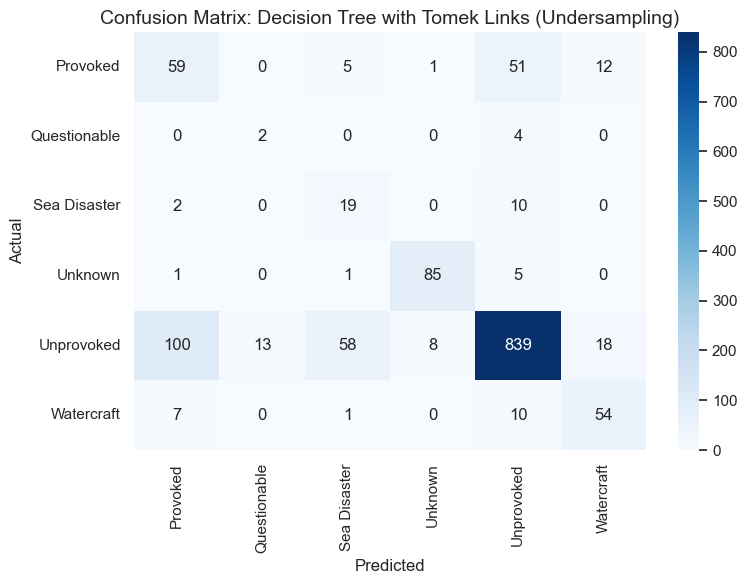

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.35      0.46      0.40       128
Questionable       0.13      0.33      0.19         6
Sea Disaster       0.23      0.61      0.33        31
     Unknown       0.90      0.92      0.91        92
  Unprovoked       0.91      0.81      0.86      1036
  Watercraft       0.64      0.75      0.69        72

    accuracy                           0.78      1365
   macro avg       0.53      0.65      0.56      1365
weighted avg       0.83      0.78      0.80      1365

Accuracy Score: 0.7751
ROC AUC Score: 0.7892
PR AUC Score: -0.7938
------------------------------------------------------------

Model: Random Forest with Tomek Links (Undersampling)
Confusion Matrix:
[[  12    0    0    1  108    7]
 [   0    0    0    0    6    0]
 [   0    0    3    0   28    0]
 [   0    0    0   83    9    0]
 [   3    0    1    4 1027    1]
 [   2    0    0    0   26   44]]


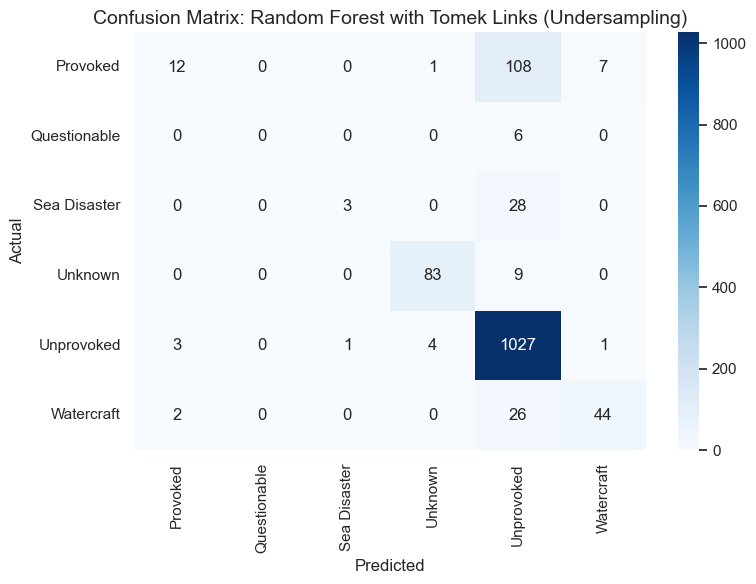

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.71      0.09      0.17       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.75      0.10      0.17        31
     Unknown       0.94      0.90      0.92        92
  Unprovoked       0.85      0.99      0.92      1036
  Watercraft       0.85      0.61      0.71        72

    accuracy                           0.86      1365
   macro avg       0.68      0.45      0.48      1365
weighted avg       0.84      0.86      0.81      1365

Accuracy Score: 0.8564
ROC AUC Score: 0.8668
PR AUC Score: -0.9169
------------------------------------------------------------

Model: Support Vector Machine with Tomek Links (Undersampling)
Confusion Matrix:
[[ 90   0   4   2  19  13]
 [  0   0   0   0   5   1]
 [  2   0  20   0   9   0]
 [  2   0   0  85   5   0]
 [124   0  50  11 829  22]
 [ 11   0   2   1   5  53]]


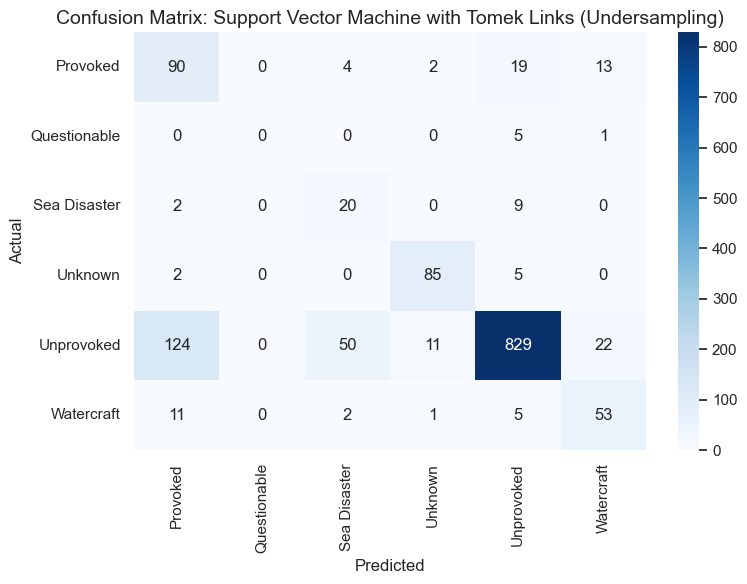

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.39      0.70      0.50       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.26      0.65      0.37        31
     Unknown       0.86      0.92      0.89        92
  Unprovoked       0.95      0.80      0.87      1036
  Watercraft       0.60      0.74      0.66        72

    accuracy                           0.79      1365
   macro avg       0.51      0.63      0.55      1365
weighted avg       0.85      0.79      0.81      1365

Accuracy Score: 0.7890
ROC AUC Score: 0.8944
PR AUC Score: -0.9162
------------------------------------------------------------

Resampling Method: SMOTE + UnderSampling

Model: Logistic Regression with SMOTE + UnderSampling
Confusion Matrix:
[[103   0   8   2   3  12]
 [  2   0   1   1   1   1]
 [  7   0  22   0   2   0]
 [  4   0   1  85   2   0]
 [371  10  94  30 500  31]
 [ 13   0   3   0   1  55]]


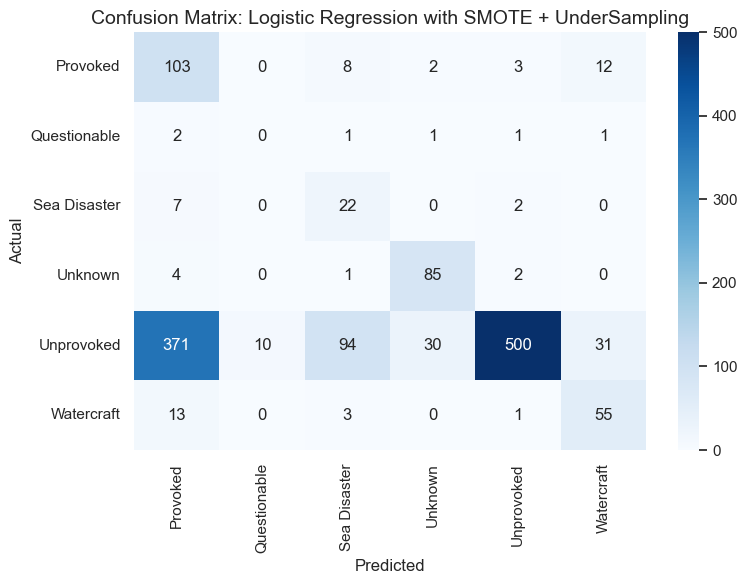

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.21      0.80      0.33       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.17      0.71      0.28        31
     Unknown       0.72      0.92      0.81        92
  Unprovoked       0.98      0.48      0.65      1036
  Watercraft       0.56      0.76      0.64        72

    accuracy                           0.56      1365
   macro avg       0.44      0.61      0.45      1365
weighted avg       0.85      0.56      0.62      1365

Accuracy Score: 0.5604
ROC AUC Score: 0.8896
PR AUC Score: -0.5966
------------------------------------------------------------

Model: Decision Tree with SMOTE + UnderSampling
Confusion Matrix:
[[ 89   4   9   7   4  15]
 [  2   2   0   2   0   0]
 [  6   0  18   0   7   0]
 [  3   1   0  86   2   0]
 [316  64 116  33 442  65]
 [ 12   0   2   0   3  55]]


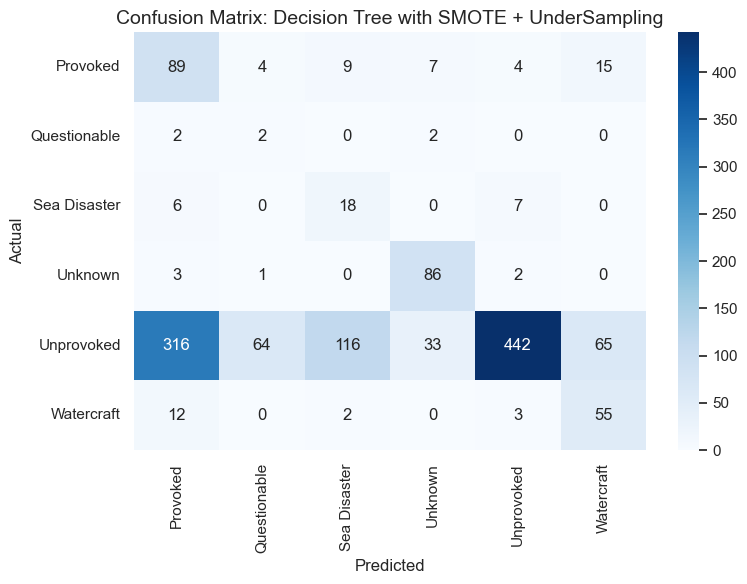

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.21      0.70      0.32       128
Questionable       0.03      0.33      0.05         6
Sea Disaster       0.12      0.58      0.20        31
     Unknown       0.67      0.93      0.78        92
  Unprovoked       0.97      0.43      0.59      1036
  Watercraft       0.41      0.76      0.53        72

    accuracy                           0.51      1365
   macro avg       0.40      0.62      0.41      1365
weighted avg       0.82      0.51      0.56      1365

Accuracy Score: 0.5070
ROC AUC Score: 0.7643
PR AUC Score: -0.5480
------------------------------------------------------------

Model: Random Forest with SMOTE + UnderSampling
Confusion Matrix:
[[110   0   6   2   2   8]
 [  2   0   0   2   2   0]
 [ 10   0  20   0   1   0]
 [  4   0   0  86   2   0]
 [553   0 123  26 293  41]
 [ 16   0   1   1   1  53]]


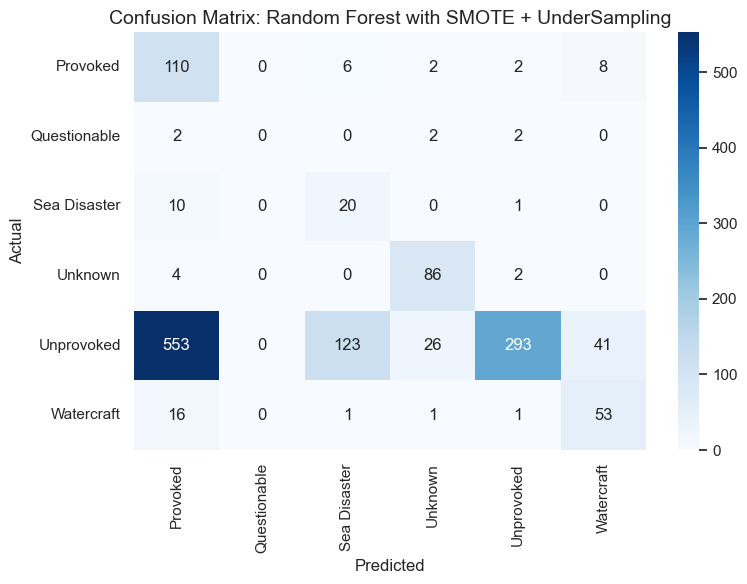

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.16      0.86      0.27       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.13      0.65      0.22        31
     Unknown       0.74      0.93      0.82        92
  Unprovoked       0.97      0.28      0.44      1036
  Watercraft       0.52      0.74      0.61        72

    accuracy                           0.41      1365
   macro avg       0.42      0.58      0.39      1365
weighted avg       0.83      0.41      0.45      1365

Accuracy Score: 0.4117
ROC AUC Score: 0.8725
PR AUC Score: -0.4749
------------------------------------------------------------

Model: Support Vector Machine with SMOTE + UnderSampling
Confusion Matrix:
[[102   0   8   2   5  11]
 [  3   0   0   0   2   1]
 [  9   0  22   0   0   0]
 [  4   0   1  85   2   0]
 [483   0 123  18 376  36]
 [ 13   0   2   1   2  54]]


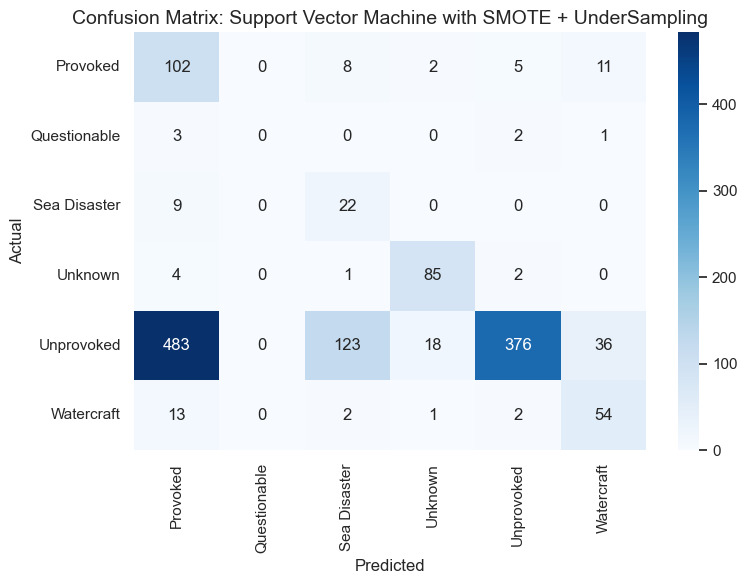

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.17      0.80      0.27       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.14      0.71      0.24        31
     Unknown       0.80      0.92      0.86        92
  Unprovoked       0.97      0.36      0.53      1036
  Watercraft       0.53      0.75      0.62        72

    accuracy                           0.47      1365
   macro avg       0.44      0.59      0.42      1365
weighted avg       0.84      0.47      0.52      1365

Accuracy Score: 0.4681
ROC AUC Score: 0.8745
PR AUC Score: -0.6100
------------------------------------------------------------


In [53]:
def pr_auc(recall, precision):
    return np.trapz(precision, recall)

X = df.drop(columns=['Type'])
y = df['Type']

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(exclude=['object']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_defs = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced'),
    "Random Forest": RandomForestClassifier(class_weight='balanced'),
    "Support Vector Machine": SVC(probability=True, class_weight='balanced')
}

resampling_methods = {
    "Random OverSampling": RandomOverSampler(random_state=42),
    "Random UnderSampling": RandomUnderSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42),
    "Tomek Links (Undersampling)": TomekLinks(sampling_strategy='majority'),
    "SMOTE + UnderSampling": SMOTEENN(random_state=42)
}

print("\n========== RESULTS USING VARIOUS RESAMPLING METHODS ==========")
for method_name, sampler in resampling_methods.items():
    print(f"\nResampling Method: {method_name}")

    X_train_prep = preprocessor.fit_transform(X_train)
    X_test_prep = preprocessor.transform(X_test)
    X_resampled, y_resampled = sampler.fit_resample(X_train_prep, y_train)

    for model_name, base_model in model_defs.items():
        print(f"\nModel: {model_name} with {method_name}")

        pipe = Pipeline([
            ('classifier', base_model)
        ])

        pipe.fit(X_resampled, y_resampled)
        y_pred = pipe.predict(X_test_prep)

        cm = confusion_matrix(y_test, y_pred)
        print("Confusion Matrix:")
        print(cm)

        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=np.unique(y), yticklabels=np.unique(y))
        plt.title(f'Confusion Matrix: {model_name} with {method_name}', fontsize=14)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.tight_layout()
        plt.show()

        print("Classification Report:")
        print(classification_report(y_test, y_pred, zero_division=0))

        acc = accuracy_score(y_test, y_pred)
        print(f"Accuracy Score: {acc:.4f}")

        y_prob = pipe.predict_proba(X_test_prep)
        if len(np.unique(y)) == 2:
            auc_score = roc_auc_score(y_test, y_prob[:, 1])
            precision, recall, _ = precision_recall_curve(y_test, y_prob[:, 1])
        else:
            y_bin = label_binarize(y_test, classes=np.unique(y))
            auc_score = roc_auc_score(y_bin, y_prob, multi_class='ovr')
            precision, recall, _ = precision_recall_curve(y_bin.ravel(), y_prob.ravel())

        pr_auc_score = pr_auc(recall, precision)
        print(f"ROC AUC Score: {auc_score:.4f}")
        print(f"PR AUC Score: {pr_auc_score:.4f}")
        print("-" * 60)


========== MODELS WITH SMOTE ==========

Resampling Method: SMOTE

Model: Logistic Regression with SMOTE
Confusion Matrix:
[[ 65   0   1   2  49  11]
 [  0   0   0   1   4   1]
 [  1   0  16   0  14   0]
 [  1   0   0  85   6   0]
 [ 39   0  20   4 964   9]
 [ 11   0   0   0   6  55]]


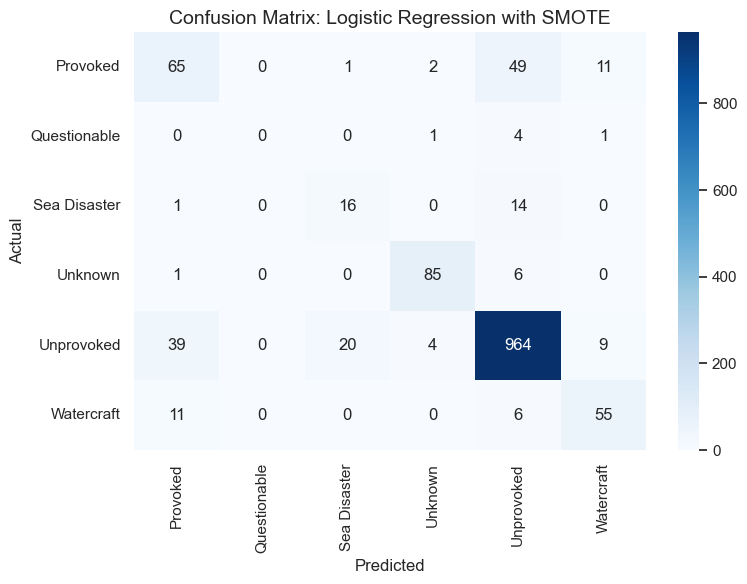

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.56      0.51      0.53       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.43      0.52      0.47        31
     Unknown       0.92      0.92      0.92        92
  Unprovoked       0.92      0.93      0.93      1036
  Watercraft       0.72      0.76      0.74        72

    accuracy                           0.87      1365
   macro avg       0.59      0.61      0.60      1365
weighted avg       0.86      0.87      0.87      1365

Accuracy Score: 0.8681


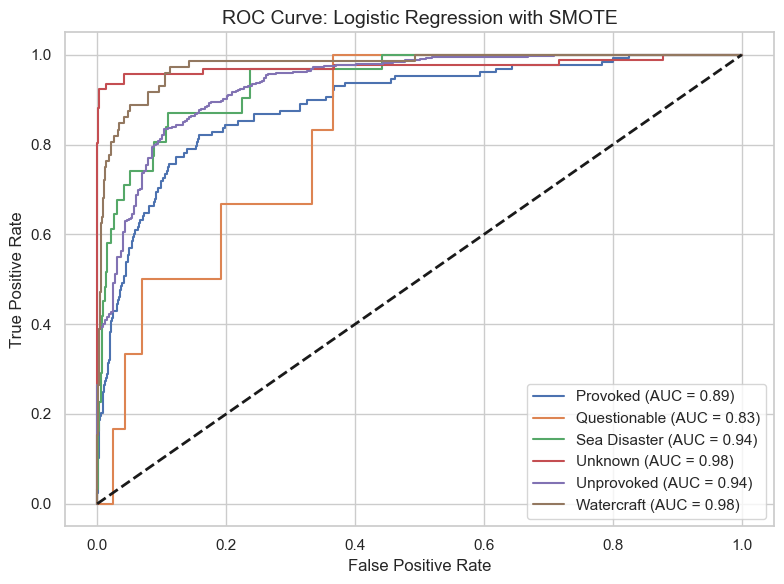

ROC AUC Score (macro-avg): 0.9248
PR AUC Score: -0.9354
------------------------------------------------------------

Model: Decision Tree with SMOTE
Confusion Matrix:
[[ 51   0   2   2  59  14]
 [  0   0   0   1   5   0]
 [  2   0  14   0  15   0]
 [  0   1   0  85   6   0]
 [ 56   3  38   7 921  11]
 [  9   0   0   0   8  55]]


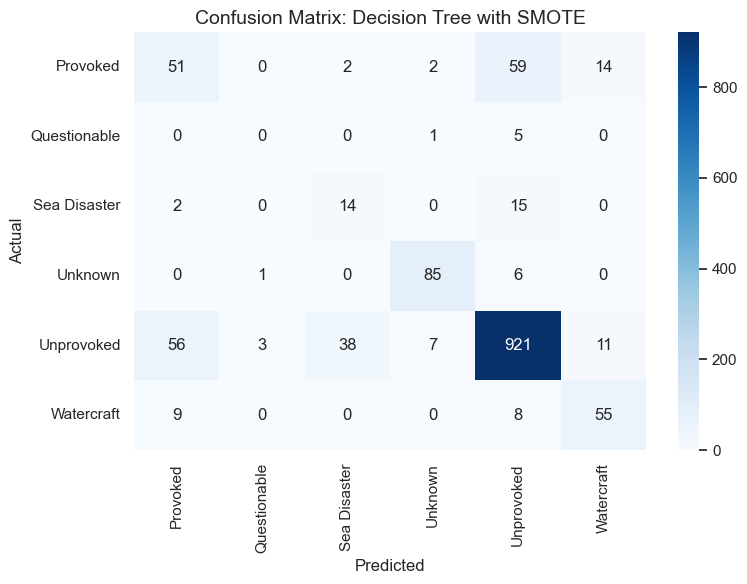

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.43      0.40      0.41       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.26      0.45      0.33        31
     Unknown       0.89      0.92      0.91        92
  Unprovoked       0.91      0.89      0.90      1036
  Watercraft       0.69      0.76      0.72        72

    accuracy                           0.82      1365
   macro avg       0.53      0.57      0.55      1365
weighted avg       0.83      0.82      0.83      1365

Accuracy Score: 0.8249


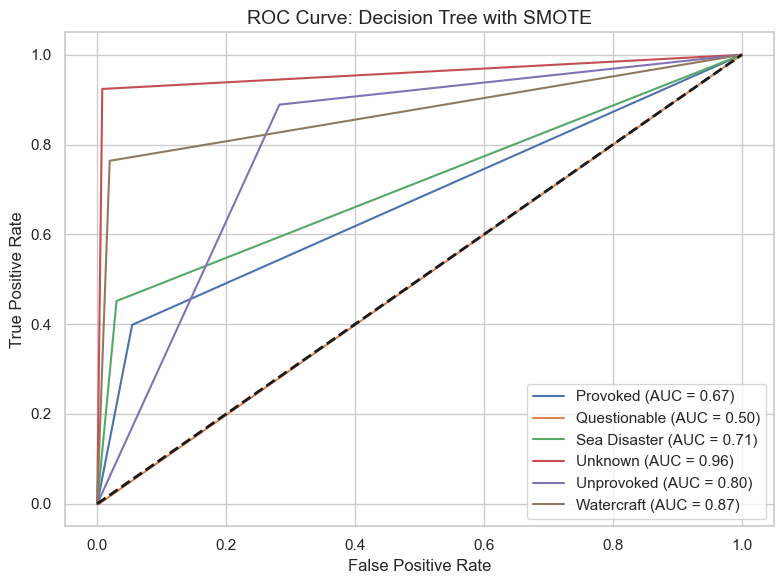

ROC AUC Score (macro-avg): 0.7525
PR AUC Score: -0.8395
------------------------------------------------------------

Model: Random Forest with SMOTE
Confusion Matrix:
[[  20    0    0    2   97    9]
 [   0    0    0    0    6    0]
 [   0    0    4    0   27    0]
 [   0    0    0   83    9    0]
 [   7    0    1    5 1021    2]
 [   4    0    0    1   24   43]]


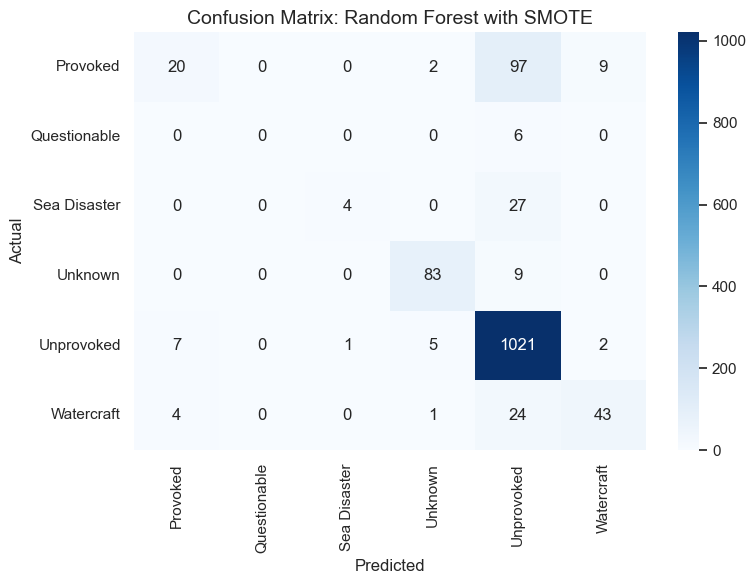

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.65      0.16      0.25       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.80      0.13      0.22        31
     Unknown       0.91      0.90      0.91        92
  Unprovoked       0.86      0.99      0.92      1036
  Watercraft       0.80      0.60      0.68        72

    accuracy                           0.86      1365
   macro avg       0.67      0.46      0.50      1365
weighted avg       0.84      0.86      0.82      1365

Accuracy Score: 0.8579


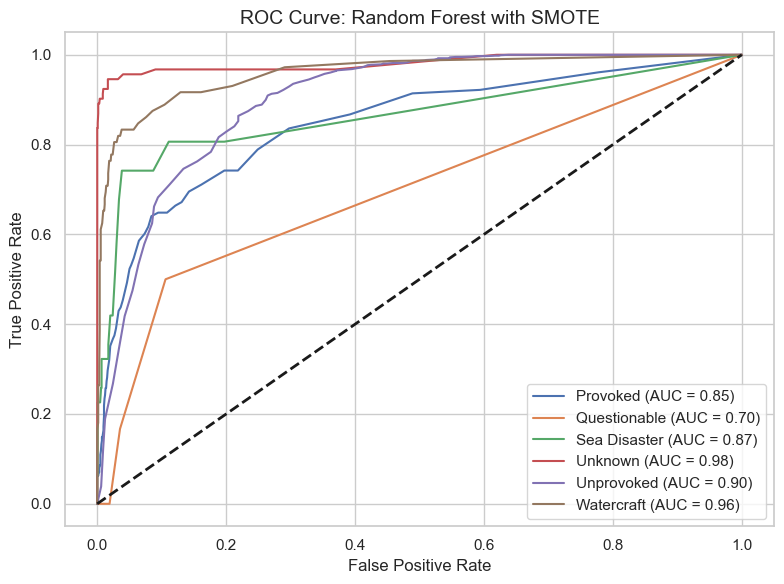

ROC AUC Score (macro-avg): 0.8747
PR AUC Score: -0.9117
------------------------------------------------------------

Model: Support Vector Machine with SMOTE
Confusion Matrix:
[[ 98   0   3   2  15  10]
 [  1   0   0   0   5   0]
 [  5   0  14   0  12   0]
 [  3   0   0  85   4   0]
 [174   0  19   9 823  11]
 [ 12   0   0   1   5  54]]


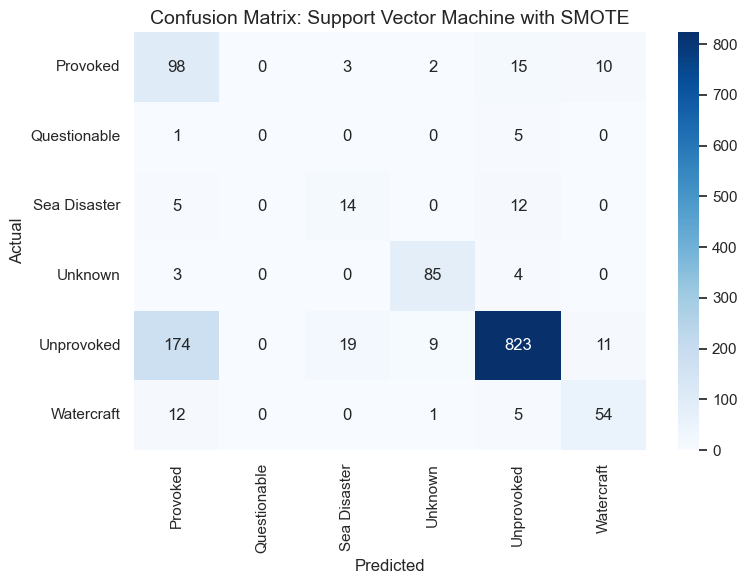

Classification Report:
              precision    recall  f1-score   support

    Provoked       0.33      0.77      0.47       128
Questionable       0.00      0.00      0.00         6
Sea Disaster       0.39      0.45      0.42        31
     Unknown       0.88      0.92      0.90        92
  Unprovoked       0.95      0.79      0.87      1036
  Watercraft       0.72      0.75      0.73        72

    accuracy                           0.79      1365
   macro avg       0.55      0.61      0.56      1365
weighted avg       0.86      0.79      0.81      1365

Accuracy Score: 0.7868


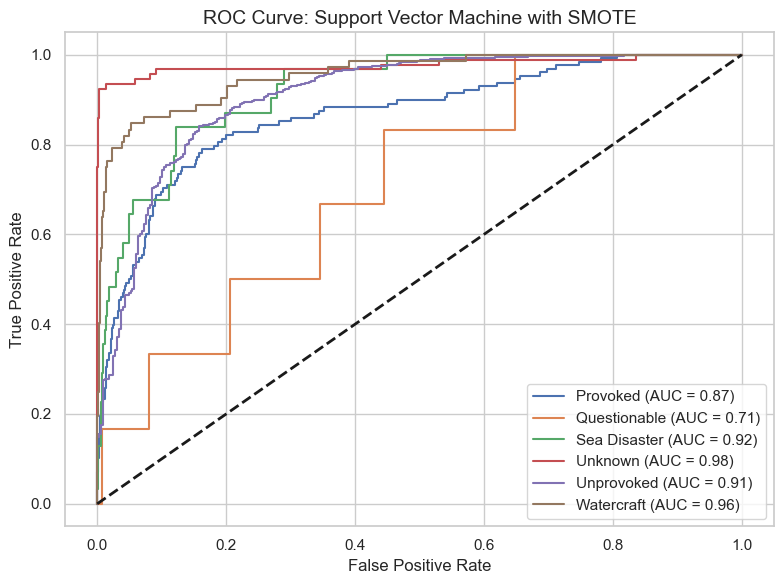

ROC AUC Score (macro-avg): 0.8902
PR AUC Score: -0.8528
------------------------------------------------------------


In [54]:
def pr_auc(recall, precision):
    return np.trapz(precision, recall)

X = df.drop(columns=['Type'])
y = df['Type']

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(exclude=['object']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_defs = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced'),
    "Random Forest": RandomForestClassifier(class_weight='balanced'),
    "Support Vector Machine": SVC(probability=True, class_weight='balanced')
}

resampling_methods = {
    "SMOTE": SMOTE(random_state=42),  
}

print("\n========== MODELS WITH SMOTE ==========")
for method_name, sampler in resampling_methods.items():
    print(f"\nResampling Method: {method_name}")

    X_train_prep = preprocessor.fit_transform(X_train)
    X_test_prep = preprocessor.transform(X_test)
    X_resampled, y_resampled = sampler.fit_resample(X_train_prep, y_train)

    for model_name, base_model in model_defs.items():
        print(f"\nModel: {model_name} with {method_name}")

        pipe = Pipeline([('classifier', base_model)])
        pipe.fit(X_resampled, y_resampled)
        y_pred = pipe.predict(X_test_prep)

        cm = confusion_matrix(y_test, y_pred)
        print("Confusion Matrix:")
        print(cm)

        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=np.unique(y), yticklabels=np.unique(y))
        plt.title(f'Confusion Matrix: {model_name} with {method_name}', fontsize=14)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.tight_layout()
        plt.show()

        print("Classification Report:")
        print(classification_report(y_test, y_pred, zero_division=0))
        acc = accuracy_score(y_test, y_pred)
        print(f"Accuracy Score: {acc:.4f}")

        y_prob = pipe.predict_proba(X_test_prep)
        classes = np.unique(y)
        y_bin = label_binarize(y_test, classes=classes)

        if y_prob.shape[1] == len(classes):  
            fpr = dict()
            tpr = dict()
            roc_auc = dict()

            for i in range(len(classes)):
                fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], y_prob[:, i])
                roc_auc[i] = roc_auc_score(y_bin[:, i], y_prob[:, i])

            plt.figure(figsize=(8, 6))
            for i in range(len(classes)):
                plt.plot(fpr[i], tpr[i], label=f'{classes[i]} (AUC = {roc_auc[i]:.2f})')

            plt.plot([0, 1], [0, 1], 'k--', lw=2)
            plt.title(f'ROC Curve: {model_name} with {method_name}', fontsize=14)
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.legend(loc='lower right')
            plt.grid(True)
            plt.tight_layout()
            plt.show()

        # PR AUC Score
        precision, recall, _ = precision_recall_curve(y_bin.ravel(), y_prob.ravel())
        pr_auc_score = pr_auc(recall, precision)
        print(f"ROC AUC Score (macro-avg): {np.mean(list(roc_auc.values())):.4f}")
        print(f"PR AUC Score: {pr_auc_score:.4f}")
        print("-" * 60)

#### Clustering with PCA: K-Means, Elbow Method and Silhouette Method

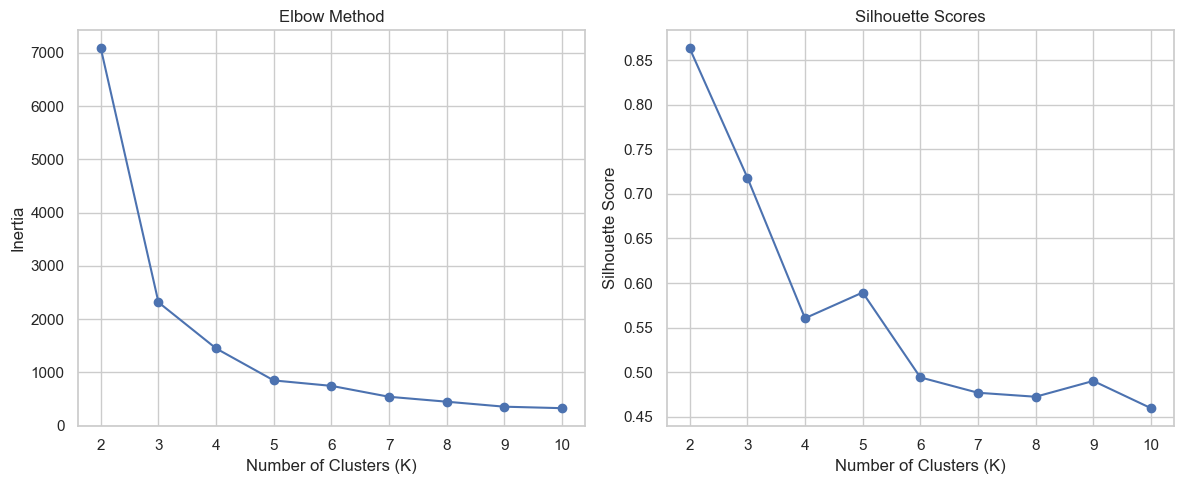


🦈 Shark Attack Risk Profile Clustering Summary:
           Avg Age     Avg Year  Fatality Rate  Number of Attacks
Cluster                                                          
0        20.775116  1968.410658       0.227273               5148
1        23.307692     0.040984       0.474576                118
2        48.535433  1999.832677       0.186638                943


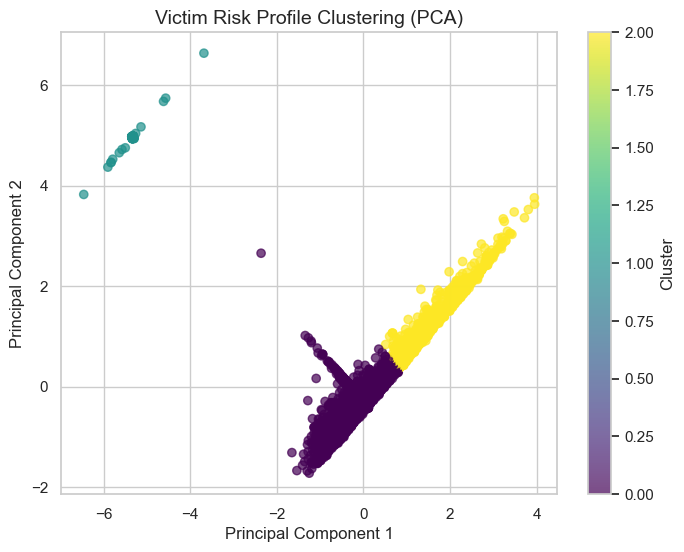

In [56]:
risk_features = ['Sex', 'Age', 'Activity', 'Year', 'Fatal']
df_risk = df[risk_features].copy()

def clean_age(value):
    try:
        if pd.isna(value):
            return np.nan
        value = str(value).strip().replace('+', '')
        return float(value) if value.replace('.', '').isdigit() else np.nan
    except:
        return np.nan

df_risk['Age'] = df_risk['Age'].apply(clean_age)

df_risk['Year'] = pd.to_numeric(df_risk['Year'], errors='coerce')

df_risk['Fatal'] = df_risk['Fatal'].str.upper().map({'Y': 1, 'N': 0})

numeric_features = ['Age', 'Year']
categorical_features = ['Sex', 'Activity']

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

X_transformed = preprocessor.fit_transform(df_risk)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_transformed)

inertia = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_pca)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_pca, kmeans.labels_))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(K_range, inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='o')
plt.title('Silhouette Scores')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

optimal_k = 3  
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42)
cluster_labels = final_kmeans.fit_predict(X_pca)

df_risk_clustered = df_risk.copy()
df_risk_clustered['Cluster'] = cluster_labels

summary = df_risk_clustered.groupby('Cluster').agg({
    'Age': 'mean',
    'Year': 'mean',
    'Fatal': ['mean', 'count']
})
summary.columns = ['Avg Age', 'Avg Year', 'Fatality Rate', 'Number of Attacks']
summary = summary.sort_index()

print("\n🦈 Shark Attack Risk Profile Clustering Summary:")
print(summary)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.7)
plt.title('Victim Risk Profile Clustering (PCA)', fontsize=14)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()


### Time Series Analysis

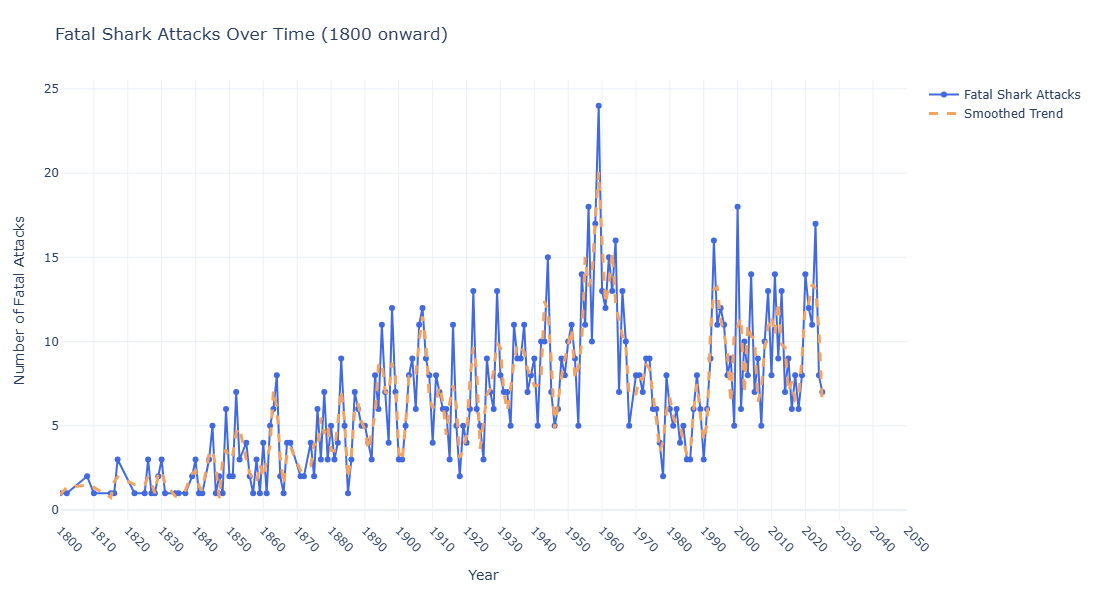

In [58]:
sns.set(style="whitegrid", palette="muted")

fatal_by_year = df[(df['Fatal'] == 'Y') & (df['Year'] >= 1800)].groupby('Year').size()

smooth_fatal_by_year = savgol_filter(fatal_by_year, window_length=5, polyorder=2)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=fatal_by_year.index,
    y=fatal_by_year.values,
    mode='lines+markers',
    name='Fatal Shark Attacks',
    line=dict(color='royalblue', width=2),
    marker=dict(size=6),
    text=[f"Year: {year}<br>Fatal Attacks: {count}" for year, count in zip(fatal_by_year.index, fatal_by_year.values)],  
    hoverinfo='text'  
))

fig.add_trace(go.Scatter(
    x=fatal_by_year.index,
    y=smooth_fatal_by_year,
    mode='lines',
    name='Smoothed Trend',
    line=dict(color='sandybrown', dash='dash', width=3)
))

fig.update_layout(
    title='Fatal Shark Attacks Over Time (1800 onward)',
    xaxis_title='Year',
    yaxis_title='Number of Fatal Attacks',
    xaxis=dict(
        tickmode='linear', 
        dtick=10,  
        tickangle=45, 
        range=[1800, 2050]  
    ),
    hovermode='closest',  
    template='plotly_white',  
    showlegend=True,
    margin=dict(l=60, r=60, t=80, b=80)
)

fig.update_layout(
    width=1000,  
    height=600  
)

fig.show()

ADF Statistic: 0.7688731149942614
p-value: 0.9911167393096515
The series is not stationary.
ADF Statistic: -2.54561766179442
p-value: 0.10476577813022259
The series is not stationary.
ADF Statistic: -5.847489444957398
p-value: 3.654560237924787e-07
The series is stationary.


C:\Users\amand\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

C:\Users\amand\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

C:\Users\amand\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:

An unsupported index was provided and will be ignored when e.g. forecasting.

C:\Users\amand\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

C:\Users\amand\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning:

Non-invertible starting MA parameters found. Using zeros as starting parameters.

C:\Users\amand\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning:

No

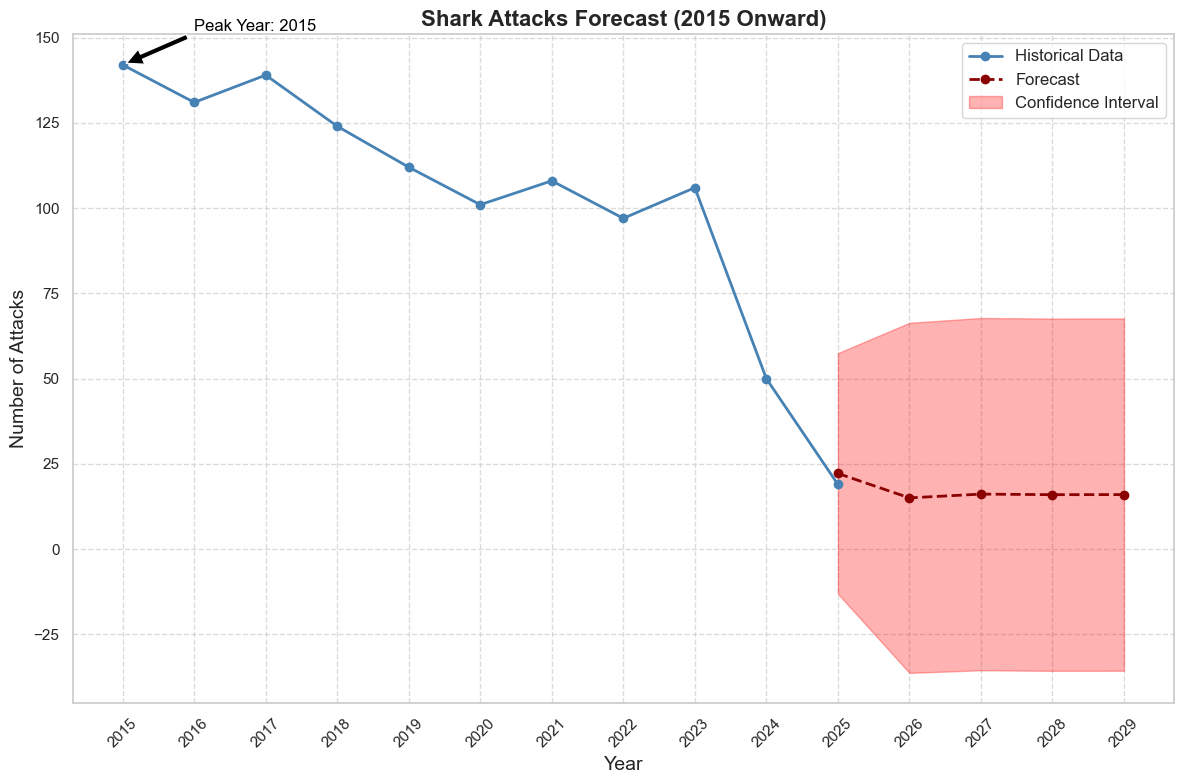

In [59]:
sns.set(style="whitegrid")

df_filtered = df[df['Year'] >= 2015]

yearly_attacks = df_filtered.groupby('Year')['Year'].count()

peak_year = yearly_attacks.idxmax()  
peak_value = yearly_attacks.max()  

def test_stationarity(series):
    result = adfuller(series)
    print(f"ADF Statistic: {result[0]}")
    print(f"p-value: {result[1]}")
    if result[1] < 0.05:
        print("The series is stationary.")
    else:
        print("The series is not stationary.")

test_stationarity(yearly_attacks)

if adfuller(yearly_attacks)[1] > 0.05:
    yearly_attacks_diff = yearly_attacks.diff().dropna()
    test_stationarity(yearly_attacks_diff)
    
    if adfuller(yearly_attacks_diff)[1] > 0.05:
        yearly_attacks_diff2 = yearly_attacks_diff.diff().dropna()
        test_stationarity(yearly_attacks_diff2)

model = ARIMA(yearly_attacks_diff2, order=(1, 0, 1))  
model_fit = model.fit()

forecast = model_fit.forecast(steps=5)
forecast_years = range(2025, 2030)

forecast_ci = model_fit.get_forecast(steps=5).conf_int()

fig, ax = plt.subplots(figsize=(12, 8))

ax.plot(yearly_attacks.index, yearly_attacks.values, label='Historical Data', marker='o', linestyle='-', color='steelblue', linewidth=2)

last_value = yearly_attacks.iloc[-1]
forecast_values = last_value + forecast  

ax.plot(forecast_years, forecast_values, label='Forecast', color='darkred', marker='o', linestyle='--', linewidth=2)

forecast_ci_adjusted = forecast_ci + last_value
ax.fill_between(forecast_years, forecast_ci_adjusted.iloc[:, 0], forecast_ci_adjusted.iloc[:, 1], color='red', alpha=0.3, label='Confidence Interval')

ax.grid(True, linestyle='--', alpha=0.7)
ax.set_title('Shark Attacks Forecast (2015 Onward)', fontsize=16, fontweight='bold')
ax.set_xlabel('Year', fontsize=14)
ax.set_ylabel('Number of Attacks', fontsize=14)
ax.set_xticks(range(2015, 2030))  
ax.set_xticklabels(range(2015, 2030), rotation=45)
ax.legend(fontsize=12)

ax.annotate(f'Peak Year: {peak_year}', xy=(peak_year, peak_value), xytext=(peak_year + 1, peak_value + 10),
            arrowprops=dict(facecolor='black', shrink=0.05), fontsize=12, color='black')

plt.tight_layout()
plt.show()